# Rapamycin after stroke in aged rats: statistical analysis

Taka Ariyaberg · Anti-stroke Project (Extended), Assignment S1 · Introduction to Scientific Research, Uppsala University

Does rapamycin given after an experimental stroke still reduce infarct size in old rats, and does the answer depend on strain or sex? The course dataset holds 64 aged rats, Wistar and spontaneously hypertensive (SHR), females and males, given rapamycin or vehicle after a stroke. Cerebral blood flow (CBF) was recorded at two sites, and infarct volume was measured 24 h after the stroke. This report takes those data from the raw spreadsheet to the final statistics.

## Summary of results

| Question | Result |
|---|---|
| Did rapamycin reduce infarct volume? | Yes. Mean infarct volume fell from 77.2 to 61.3 mm³, by 15.9 mm³ or 21 % (p < 0.001). |
| Was the reduction the same in both strains? | No (strain × treatment p = 0.003). With rapamycin, infarcts were 23.1 mm³ (31 %) smaller in Wistar rats and 8.8 mm³ (11 %) smaller in SHR. The SHR reduction is modest and borderline: Šidák p = 0.019, or 0.049 when each group keeps its own variance. |
| Was it the same in both sexes? | No detectable sex difference in the rapamycin effect overall (sex × treatment p = 0.16). In Wistar the reduction was larger in males than in females, but the three-way interaction behind this is only suggestive (§ 7.1). |
| Did collateral blood flow differ between the treatment groups? | In Wistar, treated rats lost 10.3 percentage points (pp) less collateral flow than vehicle rats; in SHR the difference (3.4 pp) was not significant. Whether this is a drug effect depends on when CBF was recorded (§ 2). |
| Did core blood flow differ? | No detectable difference: +0.9 pp (95 % CI −0.4 to 2.2), so the core ischaemia was comparably severe in both groups. The treatment difference was 5.9 pp larger at the collateral probe than at the core probe (p < 0.001). |
| Do the strains differ? | In blood flow, yes: SHR lost more flow at both probes. In infarct volume, only with rapamycin: vehicle-treated SHR and Wistar had similar infarcts (+3.2 mm³, p = 0.55), while rapamycin-treated SHR had infarcts 17.6 mm³ larger than rapamycin-treated Wistar. |
| Did sex affect any outcome? | Mainly in SHR, where females had smaller infarcts and lost less collateral flow than males. This strain × sex result does not survive every robustness check (§ 10). |
| How robust are the conclusions? | The rapamycin effect and its dependence on strain survive group-specific variances, the strict occlusion criterion and a stricter multiplicity correction. |

*ANOVA p-values are unadjusted (Holm-adjusted values are in § 7); comparisons within a strain, treatment or group are Šidák-adjusted.*

## 1. Setup and reproducibility

To run the analysis, create the conda environment once from `environment.yml`, which sits in the project's top folder next to `data/`:

```bash
conda env create -f environment.yml      # installs the pinned package versions
conda activate ISR
python -m ipykernel install --user --name ISR --display-name "Python (ISR)"
```

Then open this notebook in VS Code or JupyterLab, select the **Python (ISR)** kernel and choose **Run All**, or run it from a terminal opened in this notebook's folder:

```bash
jupyter nbconvert --to notebook --execute --inplace statistical_analysis.ipynb
python export_html.py      # rebuilds this HTML report
```

The code cells call four documented helper modules in `helpers/`, next to this notebook: `design` (factor levels and outcomes), `stats` (models, contrasts and effect sizes), `plots` (figures) and `report` (number formatting and tables).

| Safeguard | Implementation |
|---|---|
| Same input | The SHA-256 fingerprint of the raw file is checked below; any change to the spreadsheet stops the run |
| Same software | `environment.yml` pins every package the analysis imports and resolves on macOS, Windows and Linux; § 14 lists the versions used |
| Same numbers | Nothing is random: every test is closed-form, and the dot layout in the figures is deterministic |
| Same text | § 13 recomputes the key numbers quoted in the text and stops the run if one has drifted |

In [1]:
from pathlib import Path
import hashlib
import platform
import sys
from datetime import date

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import openpyxl
import pandas as pd
import scipy
import statsmodels
import statsmodels.formula.api as smf
from IPython.display import Markdown, display
from scipy import stats as sps

%config InlineBackend.figure_format = "retina"

In [2]:
RAW_FILE_NAME = "Dataset Antistroke FC.xlsx"
RAW_SHA256 = "c74ea4fc739eefca96aaddea7bdde97125ff7135c9df3249913a4d984c235332"

# This notebook's folder holds helpers/: Jupyter, VS Code and nbconvert start the kernel there, and from a
# folder above it the search goes down instead. The project root is the first folder at or above it that
# holds data/<raw file>, so the same code runs wherever the analysis folder is copied.
here = Path.cwd()
ANALYSIS_DIR = next((p for p in (here, *here.parents) if (p / "helpers" / "__init__.py").is_file()), None) \
    or next(p.parent.parent for p in sorted(here.rglob("helpers/__init__.py")))
ROOT = next(p for p in (ANALYSIS_DIR, *ANALYSIS_DIR.parents) if (p / "data" / RAW_FILE_NAME).is_file())
RAW_FILE = ROOT / "data" / RAW_FILE_NAME
CLEAN_FILE = ROOT / "data" / "processed" / "antistroke_clean.csv"
FIG_DIR = ANALYSIS_DIR / "figures"
TABLE_DIR = ANALYSIS_DIR / "tables"
for folder in (CLEAN_FILE.parent, FIG_DIR, TABLE_DIR):
    folder.mkdir(parents=True, exist_ok=True)

# Make the helper modules importable even if the kernel was started in another folder.
sys.path.insert(0, str(ANALYSIS_DIR))
from helpers import design as dz, plots as pl, report as rp, stats as st
from helpers.design import OUTCOMES, OUTCOME_BY_COLUMN
pl.set_style()

sha256 = hashlib.sha256(RAW_FILE.read_bytes()).hexdigest()
assert sha256 == RAW_SHA256, "The raw data file is not the course original. Stop and check it."

ALPHA = st.ALPHA
rp.table(pd.DataFrame({
    "Setting": ["Raw data", "SHA-256 fingerprint", "Clean data", "Figures", "Tables", "Significance level"],
    "Value": [str(RAW_FILE.relative_to(ROOT)), f"{sha256[:16]}… matches the course original",
              str(CLEAN_FILE.relative_to(ROOT)), str(FIG_DIR.relative_to(ROOT)),
              str(TABLE_DIR.relative_to(ROOT)), f"α = {ALPHA}, two-sided"],
}), caption="Run settings")

Setting,Value
Raw data,data/Dataset Antistroke FC.xlsx
SHA-256 fingerprint,c74ea4fc739eefca… matches the course original
Clean data,data/processed/antistroke_clean.csv
Figures,figures
Tables,tables
Significance level,"α = 0.05, two-sided"


## 2. Study design and research questions

Treatment was randomised and coded, and the code was broken only after the data were in. Aged animals, both sexes and a comorbidity such as hypertension are what preclinical stroke guidelines ask for once a drug has worked in young, healthy males (Fisher et al. 2009).

| Factor | Levels | Note |
|---|---|---|
| Strain | Wistar, SHR | SHR = spontaneously hypertensive rat |
| Sex | Male, Female | |
| Treatment | Vehicle, Rapamycin | Randomised and coded |

The 2 × 2 × 2 factorial gives 8 groups of 8 rats, 64 animals in all, fully crossed and balanced. Age is not a factor, since all animals are old.

| Outcome | Column in clean data | Unit | Measurement |
|---|---|---|---|
| Core CBF | `cbf_probe1_pct` | % change from baseline | Laser-Doppler probe 1, over the middle cerebral artery (MCA) core territory\* |
| Collateral CBF | `cbf_probe2_pct` | % change from baseline | Laser-Doppler probe 2, over the collateral (peri-infarct) territory\* |
| Infarct volume | `infarct_mm3` | mm³ | Tissue lost, 24 h after stroke |

\* The dataset numbers the probes without naming their positions; these are the positions in the original study (Beard et al. 2020). A value of −70 means flow fell to 30 % of its baseline.

The project brief asks which groups differ and whether sex, treatment or strain affect each outcome. Q1–Q3 answer it; Q4 goes beyond it.

| | Question | Section |
|---|---|---|
| Q1 | Do strain, sex and treatment, alone or in combination, affect each outcome? | § 7 |
| Q2 | In which strain and sex does rapamycin change each outcome, and by how much? | § 8 |
| Q3 | Which specific groups differ from each other? | § 9 |
| Q4 | Exploratory: do animals with better blood flow have smaller infarcts? | § 11 |

> **Caveat**
>
> The dataset does not say *when* CBF was recorded relative to dosing. In the original protocol rapamycin was given 30 min after occlusion, so a CBF difference between the treatment groups reads as a drug effect only if CBF was recorded after dosing. § 12.2 weighs the evidence.

## 3. Data preprocessing

The raw file is never modified. Every correction happens here, in code, where it can be seen.

### 3.1 Workbook audit

Before any value is read, the workbook's structure is checked for formulas, merged or hidden cells, comments and numbers stored as text.

In [3]:
workbook = openpyxl.load_workbook(RAW_FILE, data_only=False)
audit = []
for ws in workbook.worksheets:
    cells = [c for row in ws.iter_rows() for c in row]
    header_row = next(r for r in range(1, 6) if ws.cell(r, 1).value == "Animal no:")
    body = [c for row in ws.iter_rows(min_row=header_row + 1) for c in row]
    measures = [c.value for c in body if c.column > 4]
    audit.append({
        "Sheet": ws.title,
        "Title in A1": ws["A1"].value,
        "Header row": header_row,
        "Animals": ws.max_row - header_row,
        "Columns": ws.max_column,
        "Formulas": sum(isinstance(c.value, str) and c.value.startswith("=") for c in cells),
        "Merged cells": len(ws.merged_cells.ranges),
        "Hidden rows or columns": sum(d.hidden for d in ws.row_dimensions.values())
                                  + sum(d.hidden for d in ws.column_dimensions.values()),
        "Comments": sum(c.comment is not None for c in cells),
        "Measurements stored as": "whole numbers" if all(isinstance(v, int) for v in measures) else "mixed",
    })
rp.table(pd.DataFrame(audit).set_index("Sheet").T.rename_axis("Property").reset_index(),
         caption="Workbook audit: structure of the two sheets")

Property,CBF,Infarct
Title in A1,Changes in cerebral blood flow,Infarct volume (mm3)
Header row,2,2
Animals,64,64
Columns,6,5
Formulas,0,0
Merged cells,0,0
Hidden rows or columns,0,0
Comments,0,0
Measurements stored as,whole numbers,whole numbers


Both sheets can be read directly. Every measurement is a whole number, which limits the resolution to 1 unit and creates ties.

### 3.2 Loading and standardisation

In [4]:
# header=1 means "column names are in row 2"; row 1 holds the sheet title.
raw = {sheet: pd.read_excel(RAW_FILE, sheet_name=sheet, header=1) for sheet in ("CBF", "Infarct")}

RENAME = {
    "Animal no:": "animal_id",
    "Strain:": "strain",
    "Sex:": "sex",
    "Treatment:": "treatment",
    "CBF probe 1: (change in % from baseline)": "cbf_probe1_pct",
    "CBF probe 2: (change in % from baseline)": "cbf_probe2_pct",
    "Infarct volume (mm3)": "infarct_mm3",
}
TEXT_COLUMNS = ["animal_id", "strain", "sex", "treatment"]
rp.table(pd.DataFrame({"Raw column name": list(RENAME), "Clean name": list(RENAME.values())}),
         caption="Column names in the raw file and in the clean dataset")

Raw column name,Clean name
Animal no:,animal_id
Strain:,strain
Sex:,sex
Treatment:,treatment
CBF probe 1: (change in % from baseline),cbf_probe1_pct
CBF probe 2: (change in % from baseline),cbf_probe2_pct
Infarct volume (mm3),infarct_mm3


One problem in the text columns is invisible in Excel: trailing spaces.

In [5]:
spaces = [
    {"Sheet": sheet, "Column": col, "Animal": row["animal_id"], "Raw value": repr(row[col])}
    for sheet, frame in raw.items()
    for col in TEXT_COLUMNS
    for _, row in frame.rename(columns=RENAME).iterrows()
    if row[col] != row[col].strip()
]
display(rp.table(pd.DataFrame(spaces), caption=f"Text values with leading or trailing spaces (n = {len(spaces)})"))
print("Distinct raw values of Sex:", ", ".join(sorted(raw["CBF"]["Sex:"].map(repr).unique())))

Sheet,Column,Animal,Raw value
CBF,sex,A010,'Female '
CBF,sex,A018,'Male '
CBF,sex,A033,'Male '
CBF,sex,A058,'Female '
Infarct,sex,A010,'Female '
Infarct,sex,A018,'Male '
Infarct,sex,A033,'Male '
Infarct,sex,A058,'Female '


Distinct raw values of Sex: 'Female ', 'Female', 'Male ', 'Male'


Left as they are, `"Female "` and `"Female"` would count as two different sexes, and every model would silently fit four sex levels instead of two. The function below trims all text, then gives each variable its type: the factors become categories with a fixed level order (the first level is the reference) and the measurements become decimals.

In [6]:
def standardise(frame: pd.DataFrame) -> pd.DataFrame:
    # Rename columns, trim text, and give every variable its proper type.
    df = frame.rename(columns=RENAME)
    for col in TEXT_COLUMNS:
        df[col] = df[col].str.strip()
    for factor, levels in dz.LEVELS.items():
        unexpected = set(df[factor]) - set(levels)
        assert not unexpected, f"Unexpected {factor} values: {unexpected}"
        df[factor] = pd.Categorical(df[factor], categories=levels)
    measures = [c for c in df.columns if c.endswith(("_pct", "_mm3"))]
    df[measures] = df[measures].astype(float)
    return df

cbf, infarct = standardise(raw["CBF"]), standardise(raw["Infarct"])
columns = list(dict.fromkeys([*cbf.columns, *infarct.columns]))
rp.table(pd.DataFrame({
    "Column": columns,
    "CBF sheet": [str(cbf[c].dtype) if c in cbf else "–" for c in columns],
    "Infarct sheet": [str(infarct[c].dtype) if c in infarct else "–" for c in columns],
}), caption="Column types after standardising")

Column,CBF sheet,Infarct sheet
animal_id,str,str
strain,category,category
sex,category,category
treatment,category,category
cbf_probe1_pct,float64,–
cbf_probe2_pct,float64,–
infarct_mm3,–,float64


### 3.3 Merging and validation

In [7]:
merged = cbf.merge(infarct, on="animal_id", how="outer", suffixes=("", "_infarct_sheet"),
                   validate="one_to_one", indicator=True)
design_agrees = all((merged[f] == merged[f"{f}_infarct_sheet"]).all() for f in dz.FACTORS)
data = merged.drop(columns=[f"{f}_infarct_sheet" for f in dz.FACTORS] + ["_merge"])

cbf_values = data[["cbf_probe1_pct", "cbf_probe2_pct"]].stack()
group_sizes = data.groupby(list(dz.FACTORS), observed=False).size()
checks = [
    ("Both sheets list 64 animals", len(cbf) == len(infarct) == dz.N_TOTAL),
    ("Every animal appears in both sheets", (merged["_merge"] == "both").all()),
    ("Animal IDs are unique and run from A001 to A064",
     data["animal_id"].is_unique and sorted(data["animal_id"]) == [f"A{i:03d}" for i in range(1, 65)]),
    ("Strain, sex and treatment agree between the two sheets", design_agrees),
    ("Only the expected factor levels occur", data[list(dz.FACTORS)].notna().all().all()),
    ("Balanced design: 8 animals in each of the 8 groups",
     len(group_sizes) == 8 and (group_sizes == dz.N_PER_CELL).all()),
    ("No missing values", not data.isna().any().any()),
    ("CBF changes lie between −100 % and 0 % (a drop, at most a total loss)", cbf_values.between(-100, 0).all()),
    ("Probe 2 fell less than probe 1 in every animal", (data["cbf_probe2_pct"] > data["cbf_probe1_pct"]).all()),
    ("Occlusion confirmed: core flow fell by at least 70 % in every animal",
     (data["cbf_probe1_pct"] <= dz.OCCLUSION_THRESHOLD).all()),
    ("All infarct volumes are positive", (data["infarct_mm3"] > 0).all()),
]
validation = pd.DataFrame(checks, columns=["Check", "passed"])
validation["Result"] = np.where(validation["passed"], "pass", "FAIL")
display(rp.table(validation[["Check", "Result"]], caption="Validation checks", emphasis="Result"))
assert validation["passed"].all(), "A validation check failed: see the table above."

Check,Result
Both sheets list 64 animals,pass
Every animal appears in both sheets,pass
Animal IDs are unique and run from A001 to A064,pass
"Strain, sex and treatment agree between the two sheets",pass
Only the expected factor levels occur,pass
Balanced design: 8 animals in each of the 8 groups,pass
No missing values,pass
"CBF changes lie between −100 % and 0 % (a drop, at most a total loss)",pass
Probe 2 fell less than probe 1 in every animal,pass
Occlusion confirmed: core flow fell by at least 70 % in every animal,pass


### 3.4 Derived variables

| Column | Meaning |
|---|---|
| `group` | The experimental group, e.g. `Wistar · Male · Vehicle` (8 levels, fixed order) |
| `subgroup` | Strain × sex, e.g. `Wistar · Male` (4 levels) |
| `meets_strict_occlusion` | `True` if core flow fell by *more than* 70 % |

The original paper states its occlusion criterion two ways: "> 70 %" in the Methods and "a 70 % reduction" in the Results. Animals exactly at −70 meet one wording but not the other. The primary analysis keeps them, since they meet "at least 70 %", and § 10 repeats the analysis without them.

In [8]:
data["group"] = pd.Categorical(data[list(dz.FACTORS)].astype(str).agg(" · ".join, axis=1),
                               categories=dz.GROUP_LABELS)
data["subgroup"] = pd.Categorical(data[["strain", "sex"]].astype(str).agg(" · ".join, axis=1),
                                  categories=dz.SUBGROUP_LABELS)
data["meets_strict_occlusion"] = data["cbf_probe1_pct"] < dz.OCCLUSION_THRESHOLD

borderline = data.loc[~data["meets_strict_occlusion"], ["animal_id", "group", "cbf_probe1_pct"]]
rp.table(borderline.assign(cbf_probe1_pct=borderline["cbf_probe1_pct"].map(lambda v: rp.num(v, 0)))
         .rename(columns={"animal_id": "Animal", "group": "Group", "cbf_probe1_pct": "Core CBF (%)"}),
         caption=f"Animals exactly at the −70 % threshold (n = {len(borderline)})", right=["Core CBF (%)"])

Animal,Group,Core CBF (%)
A001,Wistar · Male · Rapamycin,−70
A006,Wistar · Female · Rapamycin,−70
A034,Wistar · Female · Rapamycin,−70
A036,Wistar · Male · Vehicle,−70
A049,Wistar · Male · Vehicle,−70
A055,Wistar · Female · Vehicle,−70


All six are Wistar, one or two in each of the four Wistar groups, so a strict "> 70 %" rule would remove Wistar animals only and unbalance the design.

### 3.5 Clean dataset

In [9]:
COLUMNS = ["animal_id", "strain", "sex", "treatment", "group", "subgroup",
           "cbf_probe1_pct", "cbf_probe2_pct", "infarct_mm3", "meets_strict_occlusion"]
data = data[COLUMNS]
data.to_csv(CLEAN_FILE, index=False, float_format="%g")

# Round trip: reading the file back must give exactly the same values.
reread = pd.read_csv(CLEAN_FILE)
measures = [o.column for o in OUTCOMES]
assert reread.shape == data.shape and np.array_equal(reread[measures].to_numpy(), data[measures].to_numpy())

dictionary = pd.DataFrame([
    ("animal_id", "text", f"{data['animal_id'].min()} to {data['animal_id'].max()}", "Animal identifier, as in the raw file"),
    ("strain", "category", ", ".join(dz.LEVELS["strain"]), "Rat strain; reference level Wistar"),
    ("sex", "category", ", ".join(dz.LEVELS["sex"]), "Sex; reference level Male"),
    ("treatment", "category", ", ".join(dz.LEVELS["treatment"]), "Randomised treatment; reference level Vehicle"),
    ("group", "category", "8 levels", "Strain · sex · treatment"),
    ("subgroup", "category", "4 levels", "Strain · sex"),
    *[(o.column, "number", f"{rp.num(data[o.column].min(), 0)} to {rp.num(data[o.column].max(), 0)}",
       f"{o.name}, {o.unit}") for o in OUTCOMES],
    ("meets_strict_occlusion", "true/false",
     f"{data['meets_strict_occlusion'].sum()} true, {(~data['meets_strict_occlusion']).sum()} false",
     "Core flow fell by more than 70 %"),
], columns=["Column", "Type", "Values", "Description"])
display(rp.table(dictionary, caption=f"Data dictionary for {CLEAN_FILE.name} ({len(data)} rows)"))
first_rows = data.head(8).drop(columns=["group", "subgroup"])
first_rows[measures] = first_rows[measures].apply(lambda col: col.map(lambda v: rp.num(v, 0)))
rp.table(first_rows, caption="The first eight animals in the clean dataset (derived group columns omitted)",
         right=measures)

Column,Type,Values,Description
animal_id,text,A001 to A064,"Animal identifier, as in the raw file"
strain,category,"Wistar, SHR",Rat strain; reference level Wistar
sex,category,"Male, Female",Sex; reference level Male
treatment,category,"Vehicle, Rapamycin",Randomised treatment; reference level Vehicle
group,category,8 levels,Strain · sex · treatment
subgroup,category,4 levels,Strain · sex
cbf_probe1_pct,number,−83 to −70,"Core CBF (probe 1), % change from baseline"
cbf_probe2_pct,number,−51 to −15,"Collateral CBF (probe 2), % change from baseline"
infarct_mm3,number,36 to 99,"Infarct volume, mm³"
meets_strict_occlusion,true/false,"58 true, 6 false",Core flow fell by more than 70 %


animal_id,strain,sex,treatment,cbf_probe1_pct,cbf_probe2_pct,infarct_mm3,meets_strict_occlusion
A001,Wistar,Male,Rapamycin,−70,−23,45,False
A002,Wistar,Female,Vehicle,−75,−28,67,True
A003,Wistar,Female,Vehicle,−75,−35,75,True
A004,Wistar,Male,Rapamycin,−71,−25,51,True
A005,Wistar,Male,Vehicle,−73,−29,80,True
A006,Wistar,Female,Rapamycin,−70,−28,61,False
A007,Wistar,Female,Rapamycin,−71,−18,63,True
A008,Wistar,Male,Vehicle,−72,−37,79,True


## 4. Statistical analysis plan

#### Key terms

| Term | Meaning |
|---|---|
| Main effect | The average difference between the two levels of one factor, averaged over the other factors |
| Interaction | One factor's effect depends on another, e.g. rapamycin helps more in one strain than in the other. With an interaction present, a main effect averages unequal effects and should not be read on its own |
| Simple effect | The effect of one factor within one level of another, e.g. the rapamycin effect in SHR only |
| Planned contrast | A comparison chosen in advance from the questions, tested against the pooled variance of the whole experiment |
| Partial η² | The share of variance a term explains once the other terms are set aside: SS(term) ÷ [SS(term) + SS(residual)]. Rough benchmarks: 0.01 small, 0.06 medium, 0.14 large |
| 95 % CI | The range of true effects compatible with the data |
| Simultaneous 95 % CIs | A set of intervals that contain their true values *together* with 95 % probability. They are wider than ordinary CIs and agree with the adjusted p-values |
| Family-wise error | The chance of at least one false positive in a set ("family") of tests |
| Holm, Šidák | Two corrections that keep the family-wise error at 5 % |
| Type III sums of squares, sum-to-zero coding | How the ANOVA divides the variance between terms: each term is tested after all the others, with effects measured as deviations from the average of both levels. In a balanced design the usual methods all give the same answer |
| HC3 | Heteroscedasticity-consistent standard errors, which let each group keep its own variance instead of assuming one shared variance |
| pp | Percentage points: the difference between two percentages. A change of −30 % vs −40 % differs by 10 pp |

#### Analysis decisions

| Decision | Choice | Rationale |
|---|---|---|
| Unit of analysis | The animal: one value per animal per outcome | Animals were randomised individually |
| Outcomes | Core CBF, collateral CBF and infarct volume, each analysed separately. Infarct volume is the key outcome for whether rapamycin protects tissue; the CBF outcomes describe the blood-flow route | The two probes measure different territories (§ 5.2); averaging them would mix two physiological quantities |
| Main model | Three-way ANOVA: strain × sex × treatment with all interactions | Mirrors the randomised 2 × 2 × 2 design. It tests directly whether one factor's effect depends on another, instead of comparing p-values from separate tests, a common error (Nieuwenhuis et al. 2011) |
| Coding | Sum-to-zero contrasts, Type III sums of squares | Tests unweighted group means. In this balanced design Types I, II and III agree (verified in § 6), and Type III stays correct in the unbalanced sensitivity analysis |
| Significance | α = 0.05, two-sided | Convention |
| Families of tests | Each outcome's ANOVA is one family (7 tests), and each set of follow-up comparisons is its own family (2 or 4 tests; 28 for Tukey in § 9). The three outcomes are not corrected against each other | They answer different questions; § 10 shows what changes under one correction across all 21 ANOVA tests |
| ANOVA terms | Holm-adjusted p-values next to the raw ones. An effect is **clear** if Holm p < 0.05 and **suggestive** if only the raw p is | With no true effects at all, the chance of at least one false positive among 7 tests would be about 30 % (1 − 0.95⁷; Cramer et al. 2016) |
| Follow-up comparisons | Šidák-adjusted p-values with simultaneous 95 % CIs | Šidák was among the post-tests of the original study, and its intervals agree with its p-values |
| Exclusions | None: all 64 animals meet the "at least 70 %" occlusion criterion (§ 3.4) | The strict "> 70 %" rule is tested as a sensitivity analysis (§ 10) |
| Outliers | Flagged, never removed on statistical grounds alone | Removing inconvenient animals biases the results |
| Descriptive statistics | Mean ± SD, not SEM | The SD describes how much animals vary, and CIs describe precision. The SEM, which the original study reported, does neither directly |

### 4.1 Detectable effect sizes

With 8 rats per group, how large must a true effect be before the design reliably detects it? The table gives the smallest effect each type of comparison detects with 80 % power, in units of the residual SD (Cohen's d) and in mm³ of infarct volume using this dataset's residual SD.

In [10]:
infarct_model = st.fit_factorial(data, "infarct_mm3")
resid_sd = float(np.sqrt(infarct_model.mse_resid))
sensitivity = st.design_sensitivity(infarct_model.df_resid, dz.N_PER_CELL)
rp.table(pd.DataFrame({
    "Comparison": sensitivity["comparison"],
    "Animals compared": sensitivity["animals"],
    "α per test": sensitivity["alpha"].map(lambda a: f"{a:.4f}"),
    "Detectable effect (SD units)": sensitivity["detectable_d"].map(lambda d: rp.num(d, 2)),
    "≈ infarct volume (mm³)": (sensitivity["detectable_d"] * resid_sd).map(rp.num),
}), caption=f"Smallest effect detected with 80 % power (residual SD of infarct volume = {rp.num(resid_sd)} mm³)",
    right=["α per test", "Detectable effect (SD units)", "≈ infarct volume (mm³)"])

Comparison,Animals compared,α per test,Detectable effect (SD units),≈ infarct volume (mm³)
"Main effect, e.g. rapamycin vs vehicle overall",32 vs 32,0.0500,0.71,6.6
"Two-way interaction, e.g. does the effect differ by strain","16 per arm, 4 arms",0.0500,1.43,13.1
Three-way interaction,"8 per arm, 8 arms",0.0500,2.85,26.2
"Rapamycin vs vehicle within one strain (Šidák, 2 comparisons)",16 vs 16,0.0253,1.11,10.2
"Rapamycin vs vehicle within one strain × sex group (Šidák, 4 comparisons)",8 vs 8,0.0127,1.71,15.8


> **Interpretation**
>
> An overall rapamycin effect of 0.71 SD (about 6.6 mm³) would be detected 80 % of the time. A comparison inside one strain × sex group needs about 1.7 SD (about 16 mm³), and the three-way interaction almost 3 SD. A non-significant result in a single subgroup is therefore not evidence that rapamycin does nothing there; its confidence interval shows which effects remain possible.

## 5. Descriptive statistics

| Question | Method | Rationale |
|---|---|---|
| How are the outcomes distributed in the eight groups? | Group means, SDs and ranges, and every animal plotted | With 8 animals per group, showing each animal is more informative than a bar chart: overlap, ties and outliers stay visible |

### 5.1 Group summaries

In [11]:
descriptives = {o.column: st.describe_groups(data, o.column) for o in OUTCOMES}
view = descriptives[OUTCOMES[0].column][["strain", "sex", "treatment", "n"]].copy()
view.columns = pd.MultiIndex.from_tuples([("", "Strain"), ("", "Sex"), ("", "Treatment"), ("", "n")])
for o in OUTCOMES:
    d = descriptives[o.column]
    view[(o.name, "Mean ± SD")] = [f"{rp.num(m)} ± {s:.1f}" for m, s in zip(d["mean"], d["sd"])]
    view[(o.name, "Range")] = [f"{rp.num(lo, 0)} to {rp.num(hi, 0)}" for lo, hi in zip(d["min"], d["max"])]

pd.concat([descriptives[o.column].assign(outcome=o.column) for o in OUTCOMES]).to_csv(
    TABLE_DIR / "table1_descriptives.csv", index=False)
rp.table(view, caption="Descriptive statistics by group (CBF in % change from baseline, infarct in mm³)",
         right=[c for c in view.columns if c[0] or c[1] == "n"])

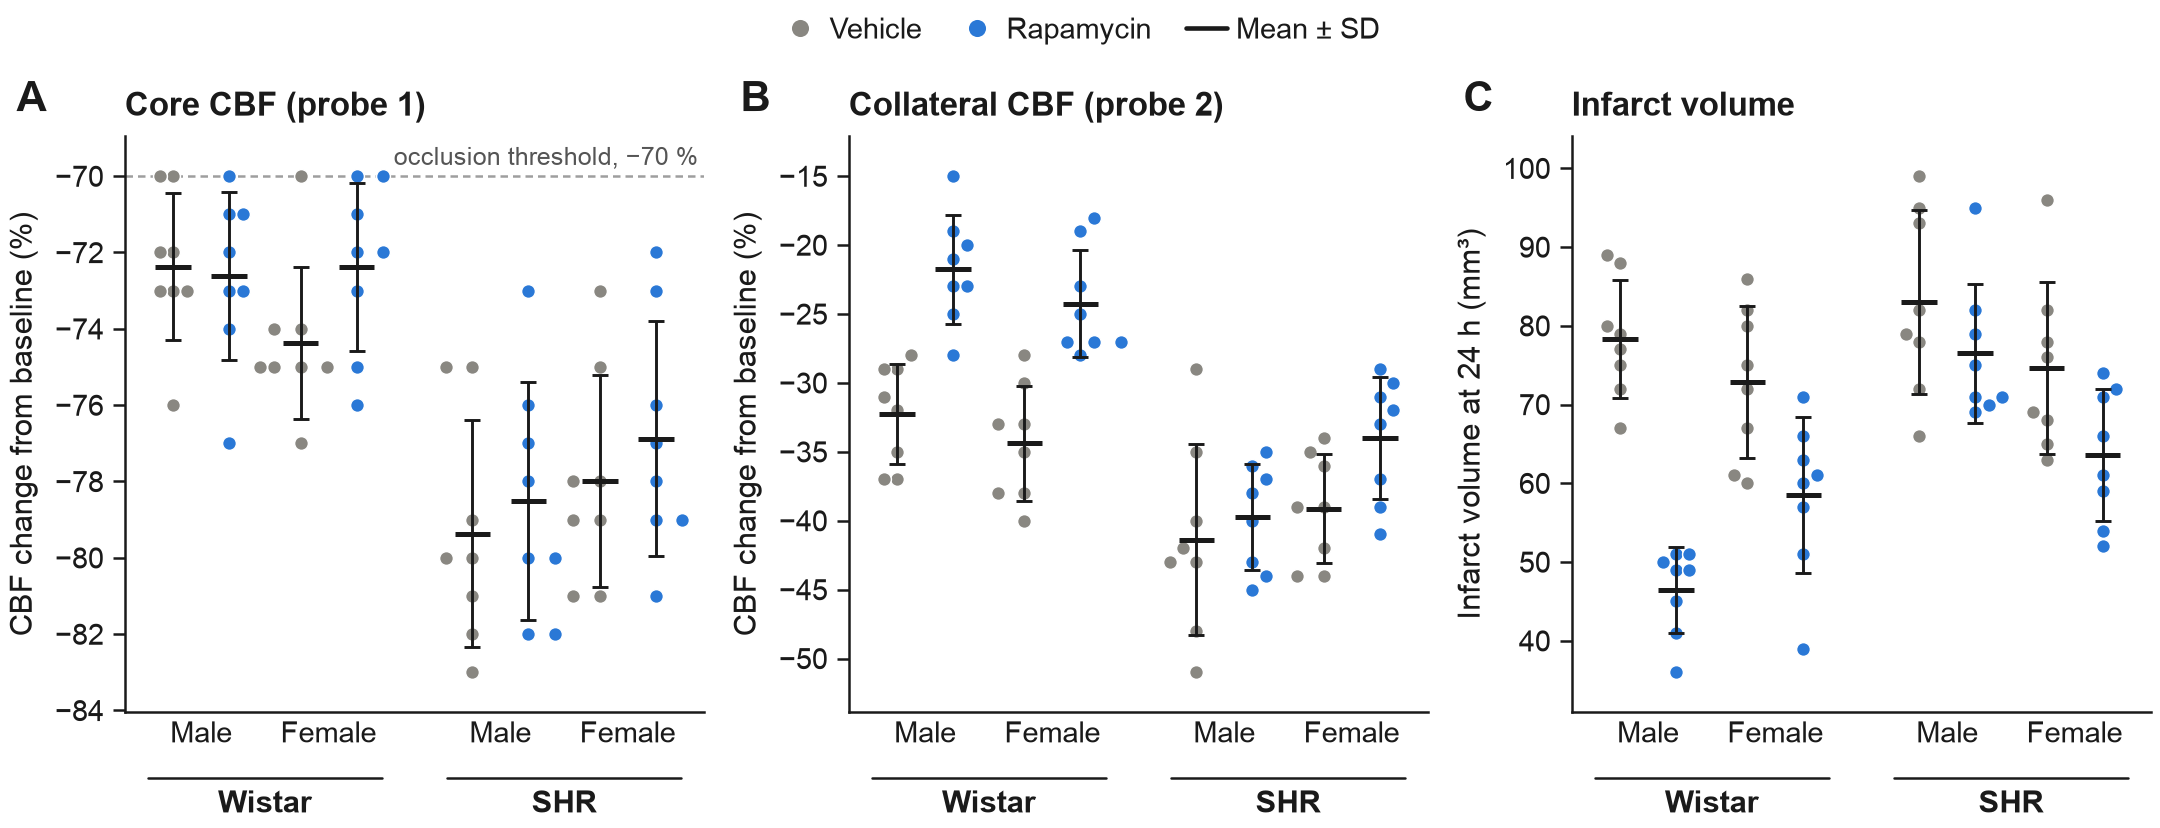

In [12]:
fig = pl.figure_individuals(data, effects={})
pl.save(fig, FIG_DIR, "fig01_individual_animals")
plt.show()

**Figure 1.** Each dot is one animal: grey for vehicle, blue for rapamycin. The black horizontal line is the group mean and the whiskers span ± 1 SD. On the core-CBF panel the dashed line marks the −70 % occlusion threshold.

> **Interpretation**
>
> The spread is somewhat wider in SHR than in Wistar, with no animal far from the rest; § 6 tests this formally.

### 5.2 Comparison of the two CBF probes

| Question | Method | Rationale |
|---|---|---|
| Is probe 2 reading a different region from probe 1? | Paired comparison of the two probes within each animal | Both probes are on the same animal, so a paired test is correct. (The original study used an unpaired test for this comparison.) |

Measure,Value
Animals where probe 2 fell less than probe 1,64 of 64
"Mean difference, probe 2 − probe 1 (95 % CI)","+42.2 pp [40.6, 43.8]"
Smallest difference in any animal,+30 pp
Paired t-test,"t(63) = 51.8, p < 0.001"


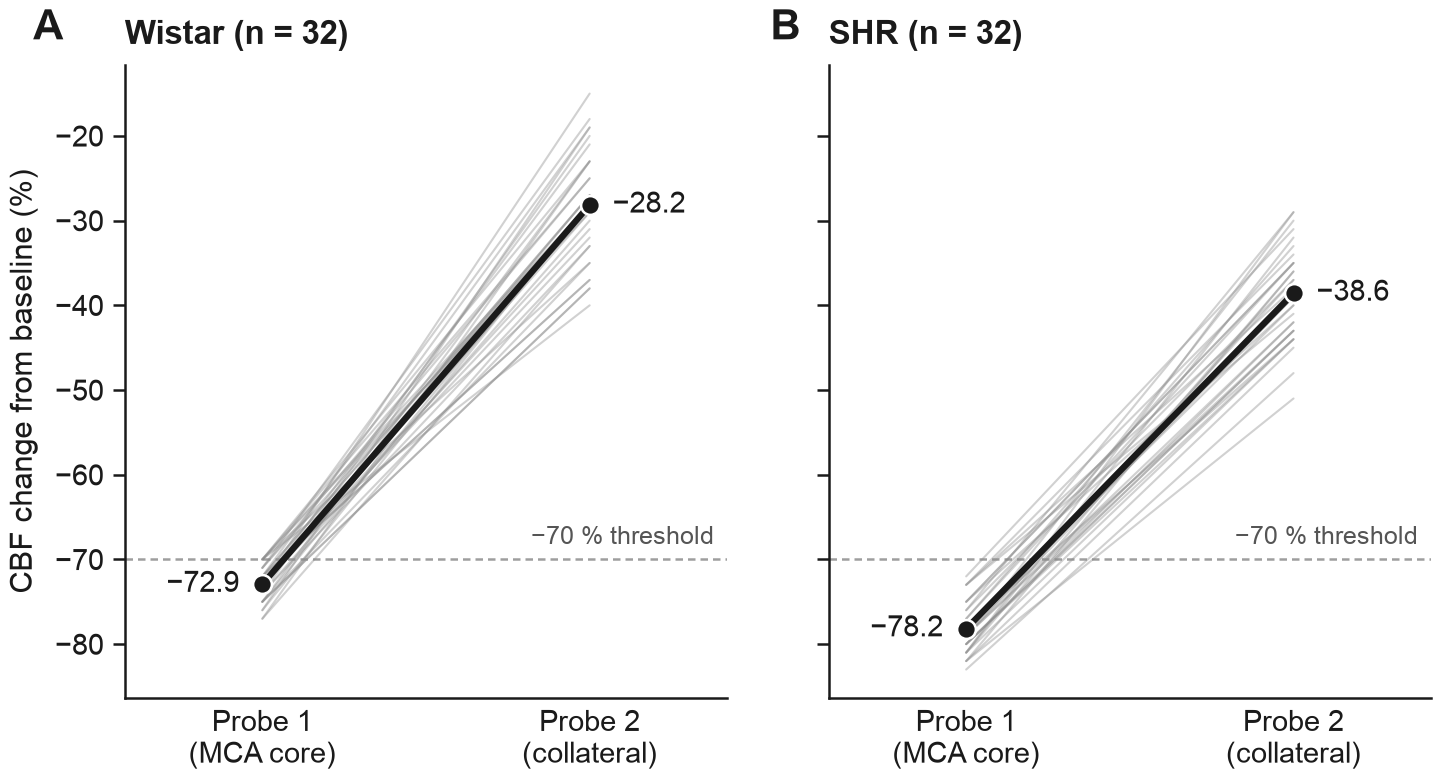

In [13]:
gap = data["cbf_probe2_pct"] - data["cbf_probe1_pct"]
paired = sps.ttest_rel(data["cbf_probe2_pct"], data["cbf_probe1_pct"])
paired_ci = paired.confidence_interval()
display(rp.table(pd.DataFrame({
    "Measure": ["Animals where probe 2 fell less than probe 1",
                "Mean difference, probe 2 − probe 1 (95 % CI)",
                "Smallest difference in any animal",
                "Paired t-test"],
    "Value": [f"{(gap > 0).sum()} of {len(gap)}",
              f"{rp.signed(gap.mean())} pp {rp.ci(paired_ci.low, paired_ci.high, 1)}",
              f"{rp.signed(gap.min(), 0)} pp",
              f"t({paired.df}) = {paired.statistic:.1f}, p {rp.fmt_p(paired.pvalue)}"],
}), caption="Probe 2 versus probe 1 within each animal"))

fig = pl.figure_probe_check(data)
pl.save(fig, FIG_DIR, "fig02_probe_check")
plt.show()

**Figure 2.** One grey line per animal joins its two probe readings; the black line joins the strain means. The dashed line marks the −70 % occlusion threshold.

> **Interpretation**
>
> The collateral probe fell less than the core probe in all 64 animals, by 42 pp on average, as in the original study. The two probes therefore read different territories and are analysed as separate outcomes.

## 6. Model diagnostics

| Question | Method | Rationale |
|---|---|---|
| Is a three-way ANOVA valid for these data? | Fit the model to each outcome, then examine its residuals: normality (Q–Q plot, Shapiro–Wilk and D'Agostino–Pearson tests), equal spread (Brown–Forsythe), outliers (studentised residuals) and influence (Cook's distance). A transformation or a rank-based method would replace the ANOVA only if these clearly failed | The F-tests assume normally distributed residuals with the same variance in every group. The assumption concerns the residuals, not the raw data, so the residuals are what is checked |

Type I, II and III sums of squares agree for all three outcomes.


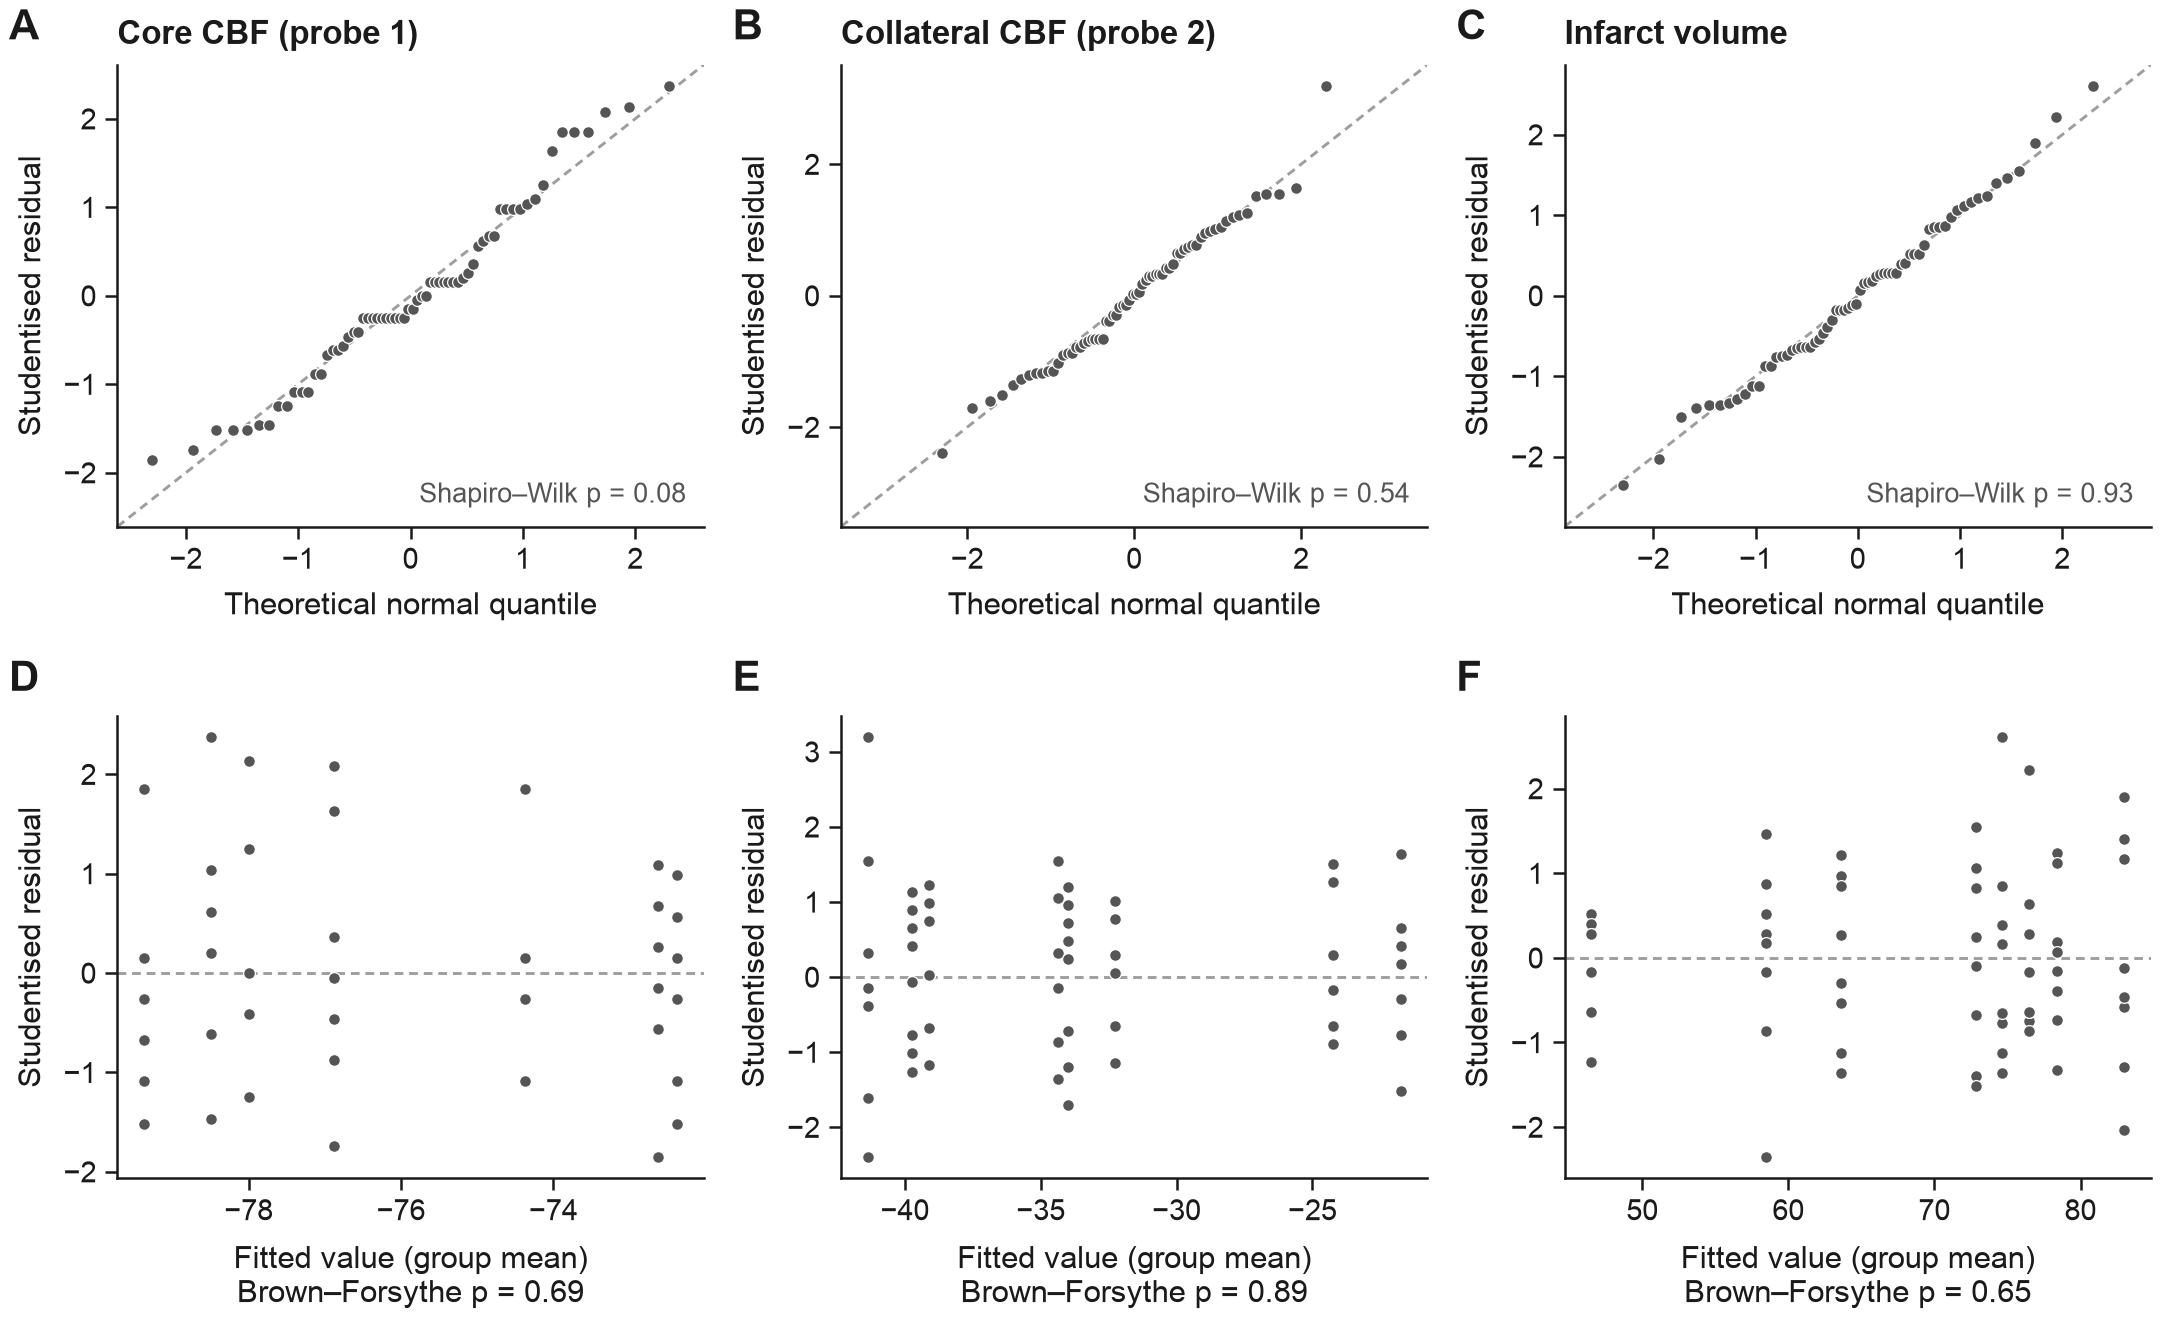

In [14]:
models = {o.column: st.fit_factorial(data, o.column) for o in OUTCOMES}
assumptions = {o.column: st.assumption_checks(data, o.column) for o in OUTCOMES}

# In a balanced design, Type I, II and III sums of squares must agree exactly.
for o in OUTCOMES:
    ss = [st.anova(models[o.column], typ=t)["sum_sq"].to_numpy() for t in (1, 2, 3)]
    assert np.allclose(ss[0], ss[1]) and np.allclose(ss[1], ss[2]), o.column
print("Type I, II and III sums of squares agree for all three outcomes.")

fig = pl.figure_diagnostics(models, assumptions)
pl.save(fig, FIG_DIR, "fig03_model_checks")
plt.show()

**Figure 3.** Top row: residuals against the values expected if they were normally distributed; points close to the line indicate normally distributed residuals. Bottom row: residuals for each group's fitted mean; similar vertical spread in every column indicates equal variances.

In [15]:
rows = []
for o in OUTCOMES:
    a = assumptions[o.column]
    met = (a["shapiro_p"] > ALPHA and a["brown_forsythe_p"] > ALPHA
           and a["outlier_p_bonferroni"] > ALPHA and a["max_cooks_d"] < 0.5)
    rows.append({
        "Outcome": o.name,
        "Shapiro–Wilk p": f"{a['shapiro_p']:.2f}",
        "D'Agostino–Pearson p": f"{a['dagostino_p']:.2f}",
        "Brown–Forsythe p": f"{a['brown_forsythe_p']:.2f}",
        "Largest ÷ smallest group SD": f"{a['sd_ratio']:.2f}",
        "Most extreme residual": f"{a['max_abs_student_resid']:.2f} ({a['max_resid_animal']})",
        "Outlier test, Bonferroni p": f"{min(a['outlier_p_bonferroni'], 1):.2f}",
        "Largest Cook's distance": f"{a['max_cooks_d']:.2f} ({a['max_cooks_animal']})",
        "Assumptions met": "pass" if met else "FAIL",
    })
assumption_table = pd.DataFrame(rows).set_index("Outcome").T.rename_axis(index="Check", columns=None).reset_index()
rp.table(assumption_table, caption="Assumption checks (p > 0.05 means no evidence of a violation)",
         right=[o.name for o in OUTCOMES])

Check,Core CBF (probe 1),Collateral CBF (probe 2),Infarct volume
Shapiro–Wilk p,0.08,0.54,0.93
D'Agostino–Pearson p,0.41,0.78,0.81
Brown–Forsythe p,0.69,0.89,0.65
Largest ÷ smallest group SD,1.62,1.90,2.14
Most extreme residual,2.37 (A025),3.19 (A063),2.61 (A064)
"Outlier test, Bonferroni p",1.00,0.15,0.75
Largest Cook's distance,0.09 (A025),0.16 (A063),0.11 (A064)
Assumptions met,pass,pass,pass


> **Interpretation**
>
> - Points follow the line in every Q–Q plot, and no normality test is significant. The stepped look for core CBF comes from whole-number values with a small spread (residual SD about 2.6 pp), not from skew.
> - Brown–Forsythe p is well above 0.05 for every outcome, and the largest group SD is at most about twice the smallest; with equal group sizes, ANOVA tolerates differences of this size well.
> - The most extreme residual (A063, collateral CBF) is not an outlier after Bonferroni correction, and no Cook's distance comes near 0.5, the usual mark of an influential point.
> - Core CBF is bounded by the occlusion criterion. No animal could show less than a 70 % core drop, and Wistar values pile up at the boundary (6 animals at exactly −70, 3 at −71). Core CBF therefore describes animals selected on that same variable, and is better read as a check on stroke severity than as an outcome in its own right.
>
> The three-way ANOVA on the raw scale is appropriate for all three outcomes. No transformation is needed, so every effect stays in the outcome's own units.

## 7. Three-way ANOVA

| Question | Method | Rationale |
|---|---|---|
| Q1: do strain, sex and treatment, alone or in combination, affect each outcome? | Three-way ANOVA per outcome (§ 4). Each term is reported as an estimated difference with its 95 % CI, raw and Holm p, and partial η² with its 95 % CI | An estimate with its CI shows the size and direction of each term, which F and p alone do not |

In the tables below, *Estimate* gives each term as a difference in the outcome's own units, signed as described under *Meaning*: Strain is SHR − Wistar, and Strain × Treatment is the rapamycin effect in SHR minus the rapamycin effect in Wistar. Bold rows are clear effects and italic rows suggestive (definitions in § 4).

### 7.1 ANOVA tables

In [16]:
anova_tables = {o.column: st.anova_table(data, o.column) for o in OUTCOMES}

def show_anova(o):
    t = anova_tables[o.column]
    return rp.table(pd.DataFrame({
        "Term": t["term"],
        "Meaning": t["meaning"],
        f"Estimate [95 % CI] ({o.diff_unit})": [rp.est_ci(e, lo, hi) for e, lo, hi in zip(t["estimate"], t["ci_low"], t["ci_high"])],
        f"F(1, {t['df_resid'].iloc[0]})": t["F"].map(lambda f: f"{f:.2f}"),
        "p": t["p"].map(rp.fmt_p),
        "p (Holm)": t["p_holm"].map(rp.fmt_p),
        "Partial η² [95 % CI]": [f"{e:.2f} {rp.ci(lo, hi)}" for e, lo, hi in zip(t["partial_eta_sq"], t["pes_ci_low"], t["pes_ci_high"])],
        "Verdict": t["verdict"],
    }), caption=f"ANOVA: {o.name}", emphasis="Verdict",
        right=[f"Estimate [95 % CI] ({o.diff_unit})", f"F(1, {t['df_resid'].iloc[0]})", "p", "p (Holm)", "Partial η² [95 % CI]"])

pd.concat([t.assign(outcome=c) for c, t in anova_tables.items()]).to_csv(TABLE_DIR / "table2_anova.csv", index=False)
for o in OUTCOMES:
    display(show_anova(o))

Term,Meaning,Estimate [95 % CI] (pp),"F(1, 56)",p,p (Holm),Partial η² [95 % CI],Verdict
Strain,SHR − Wistar,"−5.2 [−6.5, −4.0]",66.34,< 0.001,< 0.001,"0.54 [0.36, 0.66]",clear
Sex,Female − Male,"+0.3 [−1.0, 1.6]",0.24,0.630,1.000,"0.00 [0.00, 0.09]",not significant
Treatment,Rapamycin − Vehicle,"+0.9 [−0.4, 2.2]",2.12,0.151,0.757,"0.04 [0.00, 0.17]",not significant
Strain × Sex,sex difference in SHR minus in Wistar,"+2.4 [−0.2, 5.0]",3.39,0.071,0.424,"0.06 [0.00, 0.20]",not significant
Strain × Treatment,rapamycin effect in SHR minus in Wistar,"+0.1 [−2.5, 2.7]",0.01,0.923,1.000,"0.00 [0.00, 0.04]",not significant
Sex × Treatment,rapamycin effect in females minus in males,"+1.2 [−1.3, 3.8]",0.94,0.336,1.000,"0.02 [0.00, 0.13]",not significant
Strain × Sex × Treatment,Sex × Treatment interaction in SHR minus in Wistar,"−2.0 [−7.2, 3.2]",0.60,0.441,1.000,"0.01 [0.00, 0.11]",not significant


Term,Meaning,Estimate [95 % CI] (pp),"F(1, 56)",p,p (Holm),Partial η² [95 % CI],Verdict
Strain,SHR − Wistar,"−10.4 [−12.6, −8.2]",86.74,< 0.001,< 0.001,"0.61 [0.43, 0.71]",clear
Sex,Female − Male,"+0.8 [−1.4, 3.1]",0.57,0.453,1.000,"0.01 [0.00, 0.11]",not significant
Treatment,Rapamycin − Vehicle,"+6.8 [4.6, 9.1]",37.52,< 0.001,< 0.001,"0.40 [0.20, 0.55]",clear
Strain × Sex,sex difference in SHR minus in Wistar,"+6.3 [1.8, 10.8]",7.98,0.007,0.026,"0.12 [0.01, 0.29]",clear
Strain × Treatment,rapamycin effect in SHR minus in Wistar,"−6.9 [−11.4, −2.5]",9.64,0.003,0.015,"0.15 [0.02, 0.31]",clear
Sex × Treatment,rapamycin effect in females minus in males,"+1.6 [−2.9, 6.0]",0.49,0.487,1.000,"0.01 [0.00, 0.11]",not significant
Strain × Sex × Treatment,Sex × Treatment interaction in SHR minus in Wistar,"+3.9 [−5.1, 12.8]",0.75,0.390,1.000,"0.01 [0.00, 0.12]",not significant


Term,Meaning,Estimate [95 % CI] (mm³),"F(1, 56)",p,p (Holm),Partial η² [95 % CI],Verdict
Strain,SHR − Wistar,"+10.4 [5.8, 15.0]",20.32,< 0.001,< 0.001,"0.27 [0.09, 0.43]",clear
Sex,Female − Male,"−3.7 [−8.3, 0.9]",2.57,0.115,0.230,"0.04 [0.00, 0.18]",not significant
Treatment,Rapamycin − Vehicle,"−15.9 [−20.5, −11.3]",47.95,< 0.001,< 0.001,"0.46 [0.26, 0.60]",clear
Strain × Sex,sex difference in SHR minus in Wistar,"−13.9 [−23.1, −4.7]",9.09,0.004,0.015,"0.14 [0.02, 0.30]",clear
Strain × Treatment,rapamycin effect in SHR minus in Wistar,"+14.4 [5.2, 23.6]",9.75,0.003,0.014,"0.15 [0.02, 0.31]",clear
Sex × Treatment,rapamycin effect in females minus in males,"+6.5 [−2.7, 15.7]",1.99,0.163,0.230,"0.03 [0.00, 0.16]",not significant
Strain × Sex × Treatment,Sex × Treatment interaction in SHR minus in Wistar,"−22.0 [−40.4, −3.6]",5.71,0.020,0.061,"0.09 [0.00, 0.25]",suggestive


> **Interpretation**
>
> - Core CBF differed by strain only: SHR lost 5.2 pp more core flow than Wistar. The treatment groups showed no detectable difference, +0.9 pp (95 % CI −0.4 to 2.2), so the core ischaemia was comparably severe in both.
> - Collateral CBF had four clear terms. SHR lost 10.4 pp more collateral flow than Wistar, and rapamycin-treated rats lost 6.8 pp less than vehicle rats, a difference 6.9 pp smaller in SHR than in Wistar (strain × treatment). The sex difference also differed between the strains (strain × sex, § 7.3).
> - Rapamycin reduced infarct volume by 15.9 mm³ on average, the largest effect on infarct volume (partial η² = 0.46), and the reduction was 14.4 mm³ smaller in SHR (strain × treatment). SHR infarcts were 10.4 mm³ larger on average, but because of the interaction this strain main effect cannot be read on its own (§ 7.3). The sex difference in infarct volume depended on strain (strain × sex), and the three-way interaction is only suggestive (p = 0.020 before and 0.061 after Holm correction).
> - Sex on its own had no detectable effect on any outcome and no detectable influence on the size of the rapamycin effect (sex × treatment).

### 7.2 Effect sizes and interactions

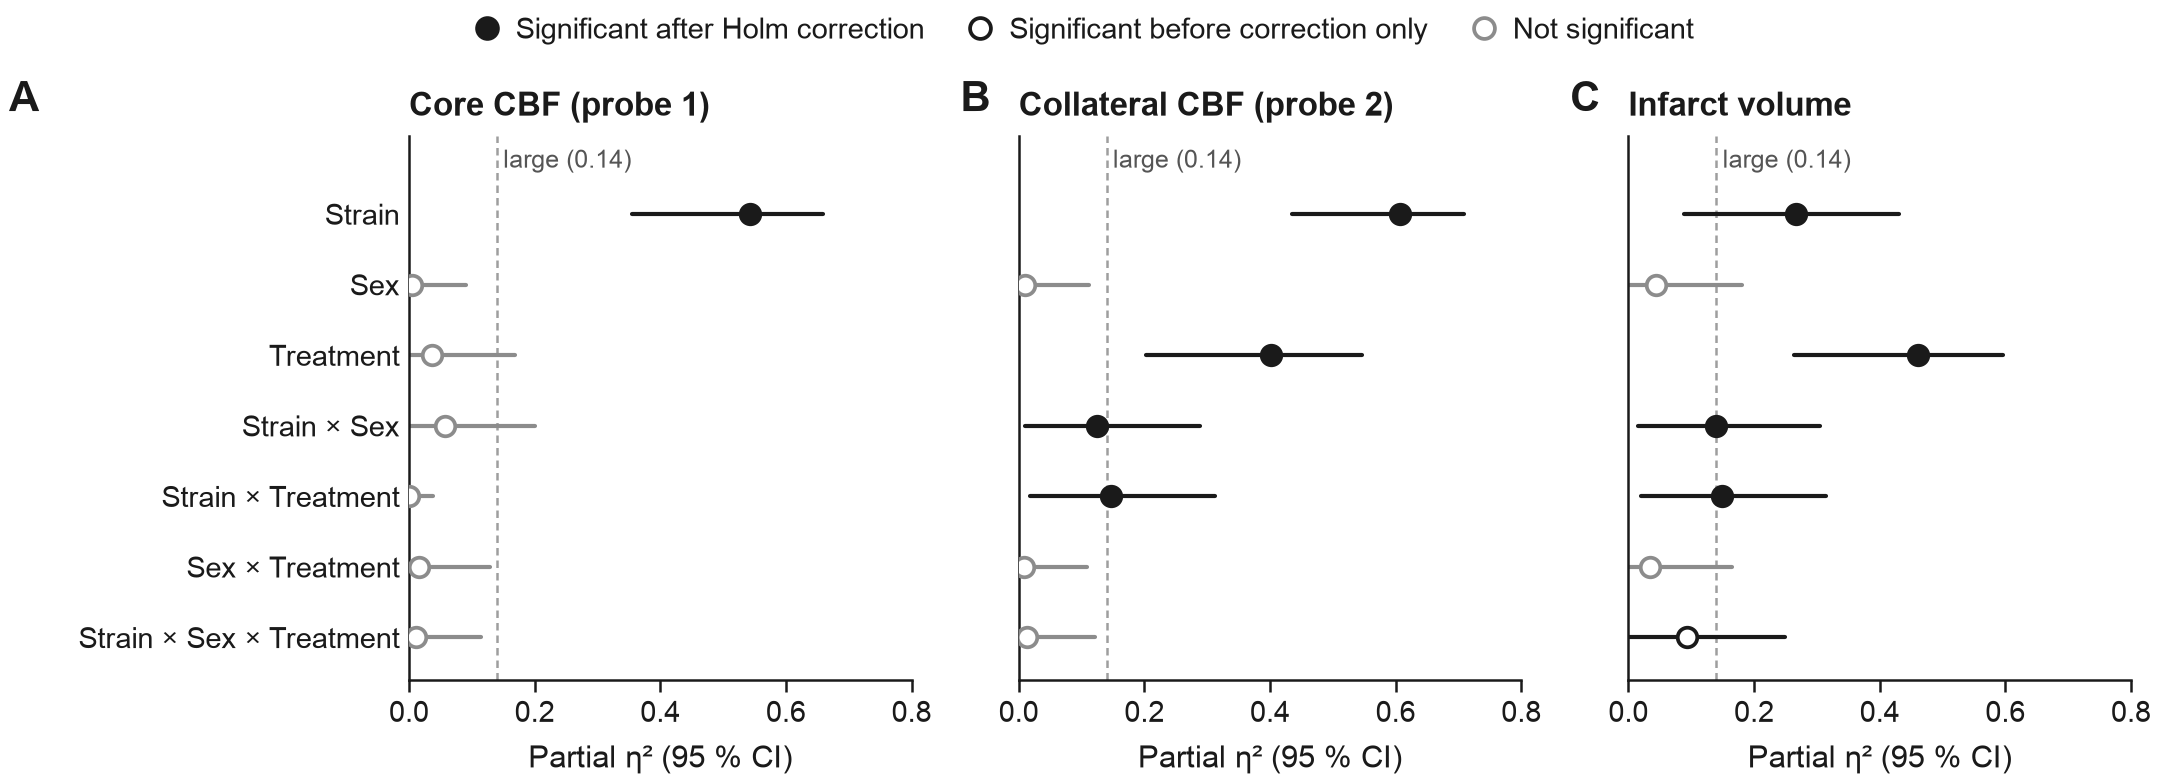

In [17]:
fig = pl.figure_effect_sizes(anova_tables)
pl.save(fig, FIG_DIR, "fig04_effect_sizes")
plt.show()

**Figure 4.** Partial η² for each term, with its 95 % CI. Filled dots are clear effects, open black dots suggestive, open grey dots not significant. The dashed line marks 0.14, conventionally a "large" effect.

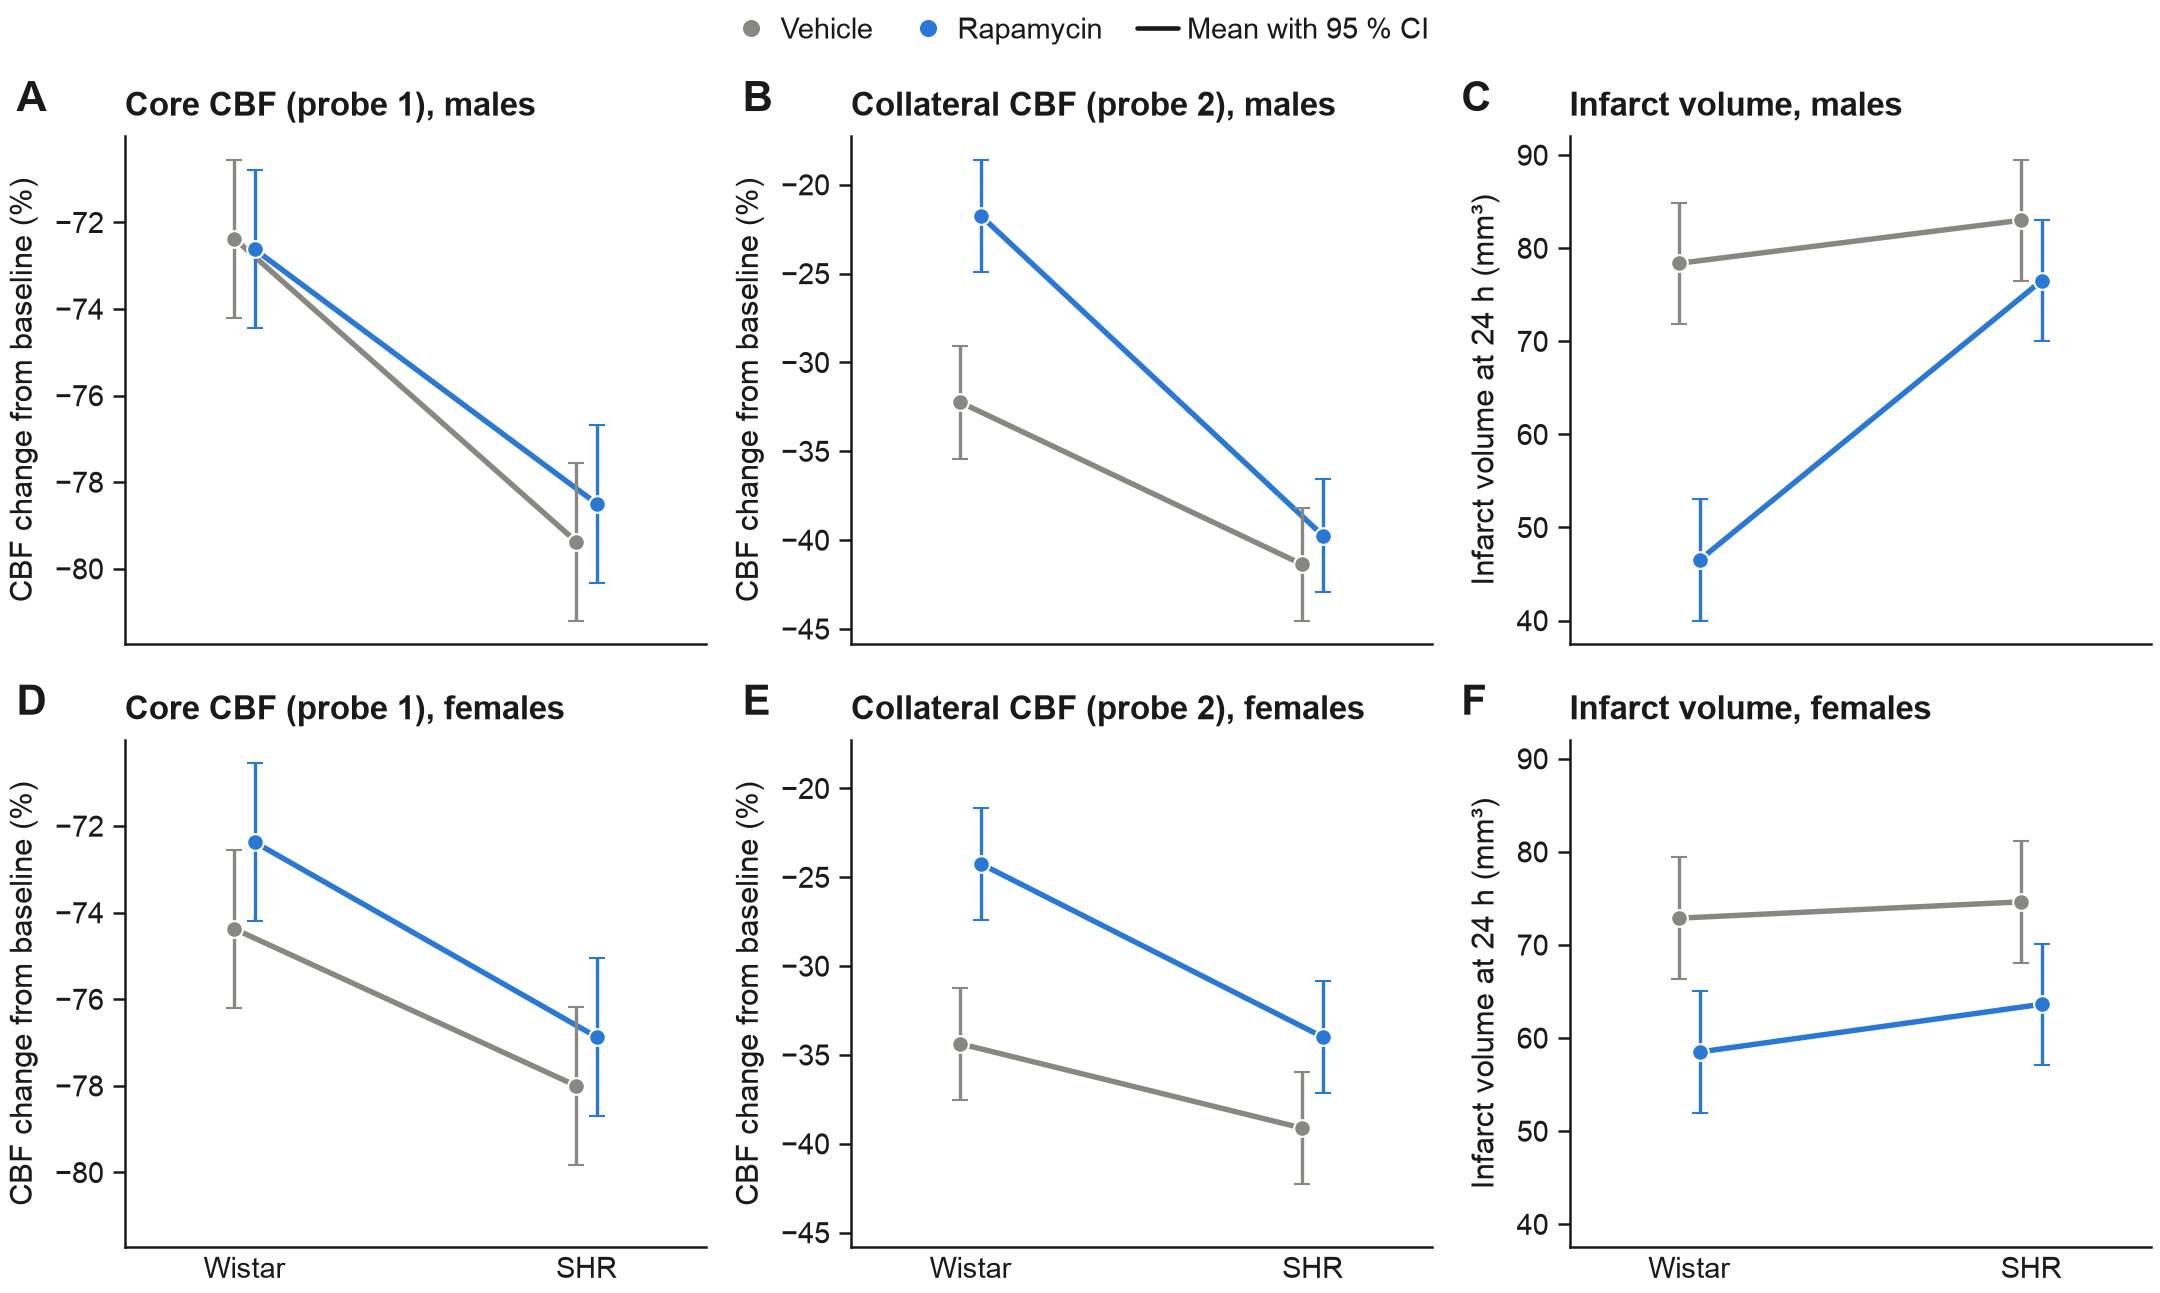

In [18]:
cell_cis = {o.column: st.cell_means_ci(data, o.column) for o in OUTCOMES}
fig = pl.figure_interactions(cell_cis)
pl.save(fig, FIG_DIR, "fig05_interactions")
plt.show()

**Figure 5.** Group means by strain, sex and treatment, with 95 % CIs from the model. The vertical gap between the blue and grey lines is the rapamycin − vehicle difference. A gap that is wider at Wistar than at SHR is the strain × treatment interaction; a pattern that also differs between the male and female rows is the three-way interaction.

> **Interpretation**
>
> For Wistar infarcts the gap is much wider in males than in females, while in SHR it is similar in both sexes; that uneven pattern is the suggestive three-way interaction.

### 7.3 Simple effects of strain and sex

| Question | Method | Rationale |
|---|---|---|
| Strain × treatment and strain × sex are clear for collateral CBF and infarct volume. Where do the strains and the sexes differ? | Strain difference (SHR − Wistar) within each treatment, and sex difference (female − male) within each strain, each averaged over the remaining factor; Šidák over the 2 comparisons | Shows where the differences behind the two interactions lie, instead of averaging them away |

In [19]:
strain_effects = {o.column: st.simple_effects(data, o.column, "strain", "treatment") for o in OUTCOMES}
sex_effects = {o.column: st.simple_effects(data, o.column, "sex", "strain") for o in OUTCOMES}

def show_simple(effects_by_outcome, label, caption):
    rows = []
    for o in OUTCOMES:
        for _, r in effects_by_outcome[o.column].iterrows():
            rows.append({"Outcome": o.name, "Within": r["within"],
                         f"{label} [95 % simultaneous CI]": f"{rp.est_ci(r['estimate'], r['ci_low'], r['ci_high'])} {o.diff_unit}",
                         "p (Šidák, 2)": rp.fmt_p(r["p_sidak"]),
                         "Verdict": "clear" if r["p_sidak"] < ALPHA else "not significant"})
    return rp.table(pd.DataFrame(rows), caption=caption, emphasis="Verdict",
                    right=[f"{label} [95 % simultaneous CI]", "p (Šidák, 2)"])

pd.concat([t.assign(outcome=c, factor="strain") for c, t in strain_effects.items()]
          + [t.assign(outcome=c, factor="sex") for c, t in sex_effects.items()]).to_csv(
    TABLE_DIR / "table3_strain_and_sex_follow_ups.csv", index=False)
display(show_simple(strain_effects, "SHR − Wistar", "Strain difference within each treatment, averaged over sex"))
display(show_simple(sex_effects, "Female − male", "Sex difference within each strain, averaged over treatment"))

Outcome,Within,SHR − Wistar [95 % simultaneous CI],"p (Šidák, 2)",Verdict
Core CBF (probe 1),Vehicle,"−5.3 [−7.4, −3.2] pp",< 0.001,clear
Core CBF (probe 1),Rapamycin,"−5.2 [−7.3, −3.1] pp",< 0.001,clear
Collateral CBF (probe 2),Vehicle,"−6.9 [−10.6, −3.3] pp",< 0.001,clear
Collateral CBF (probe 2),Rapamycin,"−13.9 [−17.5, −10.2] pp",< 0.001,clear
Infarct volume,Vehicle,"+3.2 [−4.3, 10.7] mm³",0.553,not significant
Infarct volume,Rapamycin,"+17.6 [10.1, 25.0] mm³",< 0.001,clear


Outcome,Within,Female − male [95 % simultaneous CI],"p (Šidák, 2)",Verdict
Core CBF (probe 1),Wistar,"−0.9 [−3.0, 1.2] pp",0.566,not significant
Core CBF (probe 1),SHR,"+1.5 [−0.6, 3.6] pp",0.200,not significant
Collateral CBF (probe 2),Wistar,"−2.3 [−5.9, 1.3] pp",0.276,not significant
Collateral CBF (probe 2),SHR,"+4.0 [0.4, 7.6] pp",0.028,clear
Infarct volume,Wistar,"+3.2 [−4.2, 10.7] mm³",0.541,not significant
Infarct volume,SHR,"−10.6 [−18.1, −3.1] mm³",0.004,clear


> **Interpretation**
>
> - Among vehicle rats, SHR and Wistar infarcts were similar (+3.2 mm³, p = 0.55); among rapamycin rats, SHR infarcts were 17.6 mm³ larger. The strain main effect on infarct volume therefore comes mainly from rapamycin helping SHR less rather than from larger strokes in SHR. Blood flow differs between the strains in both arms: SHR lost more collateral flow with and without treatment, and about 5 pp more core flow in both.
> - The sex difference is confined to SHR, where females had infarcts 10.6 mm³ smaller than males and lost 4.0 pp less collateral flow. Wistar showed no detectable sex difference in any outcome.

## 8. Rapamycin versus vehicle

| Question | Method | Rationale |
|---|---|---|
| Q2: in which strain and sex does rapamycin change each outcome, and by how much? | Planned contrasts from the ANOVA model: rapamycin − vehicle within each strain (2 comparisons) and within each strain × sex group (4 comparisons), Šidák-adjusted, with the % change vs vehicle for infarct volume | The comparisons follow from Q2, not from the results, and the strain × treatment interaction in § 7 shows that strain-specific estimates are needed. Contrasts use the pooled variance of the whole experiment, which is more precise than separate t-tests |

### 8.1 Effects by strain and by strain × sex group

In [20]:
effects = {o.column: st.rapamycin_effects(data, o.column, relative=o.relative) for o in OUTCOMES}

def show_effects(o):
    e = effects[o.column]
    view = pd.DataFrame({
        "Comparison": [f"{s} · {x.lower() if x == 'Both sexes' else x}" for s, x in zip(e["strain"], e["sex"])],
        "Vehicle mean": e["vehicle_mean"].map(rp.num),
        "Rapamycin mean": e["rapamycin_mean"].map(rp.num),
        f"Difference [95 % simultaneous CI] ({o.diff_unit})": [rp.est_ci(v, lo, hi) for v, lo, hi in zip(e["estimate"], e["ci_low"], e["ci_high"])],
    })
    if o.relative:
        view["% change vs vehicle [≈ 95 % CI]"] = [f"{rp.signed(v, 0)} % [{rp.num(lo, 0)}, {rp.num(hi, 0)}]"
                                                   for v, lo, hi in zip(e["pct_of_vehicle"], e["pct_ci_low"], e["pct_ci_high"])]
    view["Cohen's d"] = e["cohens_d"].map(lambda v: rp.signed(v, 2))
    view["p (Šidák)"] = e["p_sidak"].map(rp.fmt_p)
    view["Verdict"] = np.where(e["p_sidak"] < ALPHA, "clear", "not significant")
    return rp.table(view, caption=f"Rapamycin − vehicle: {o.name}. Šidák adjustment over the 2 strains (sexes pooled) "
                                  "and over the 4 strain × sex groups",
                    emphasis="Verdict", right=[c for c in view.columns if c not in ("Comparison", "Verdict")])

pd.concat([t.assign(outcome=c) for c, t in effects.items()]).to_csv(TABLE_DIR / "table4_rapamycin_effects.csv", index=False)
for o in OUTCOMES:
    display(show_effects(o))

Comparison,Vehicle mean,Rapamycin mean,Difference [95 % simultaneous CI] (pp),Cohen's d,p (Šidák),Verdict
Wistar · both sexes,−73.4,−72.5,"+0.9 [−1.2, 3.0]",+0.34,0.566,not significant
SHR · both sexes,−78.7,−77.7,"+1.0 [−1.1, 3.1]",+0.39,0.478,not significant
Wistar · Male,−72.4,−72.6,"−0.2 [−3.6, 3.1]",−0.10,0.999,not significant
Wistar · Female,−74.4,−72.4,"+2.0 [−1.3, 5.3]",+0.78,0.418,not significant
SHR · Male,−79.4,−78.5,"+0.9 [−2.4, 4.2]",+0.34,0.938,not significant
SHR · Female,−78.0,−76.9,"+1.1 [−2.2, 4.4]",+0.44,0.858,not significant


Comparison,Vehicle mean,Rapamycin mean,Difference [95 % simultaneous CI] (pp),Cohen's d,p (Šidák),Verdict
Wistar · both sexes,−33.3,−23.0,"+10.3 [6.7, 13.9]",+2.31,< 0.001,clear
SHR · both sexes,−40.2,−36.9,"+3.4 [−0.3, 7.0]",+0.76,0.073,not significant
Wistar · Male,−32.2,−21.8,"+10.5 [4.7, 16.3]",+2.35,< 0.001,clear
Wistar · Female,−34.4,−24.2,"+10.1 [4.4, 15.9]",+2.27,< 0.001,clear
SHR · Male,−41.4,−39.8,"+1.6 [−4.1, 7.4]",+0.36,0.921,not significant
SHR · Female,−39.1,−34.0,"+5.1 [−0.6, 10.9]",+1.15,0.099,not significant


Comparison,Vehicle mean,Rapamycin mean,Difference [95 % simultaneous CI] (mm³),% change vs vehicle [≈ 95 % CI],Cohen's d,p (Šidák),Verdict
Wistar · both sexes,75.6,52.5,"−23.1 [−30.6, −15.6]","−31 % [−40, −21]",−2.51,< 0.001,clear
SHR · both sexes,78.8,70.1,"−8.8 [−16.2, −1.3]","−11 % [−21, −2]",−0.95,0.019,clear
Wistar · Male,78.4,46.5,"−31.9 [−43.7, −20.0]","−41 % [−56, −26]",−3.46,< 0.001,clear
Wistar · Female,72.9,58.5,"−14.4 [−26.2, −2.5]","−20 % [−36, −3]",−1.56,0.011,clear
SHR · Male,83.0,76.5,"−6.5 [−18.3, 5.3]","−8 % [−22, 6]",−0.71,0.510,not significant
SHR · Female,74.6,63.6,"−11.0 [−22.8, 0.8]","−15 % [−31, 1]",−1.19,0.079,not significant


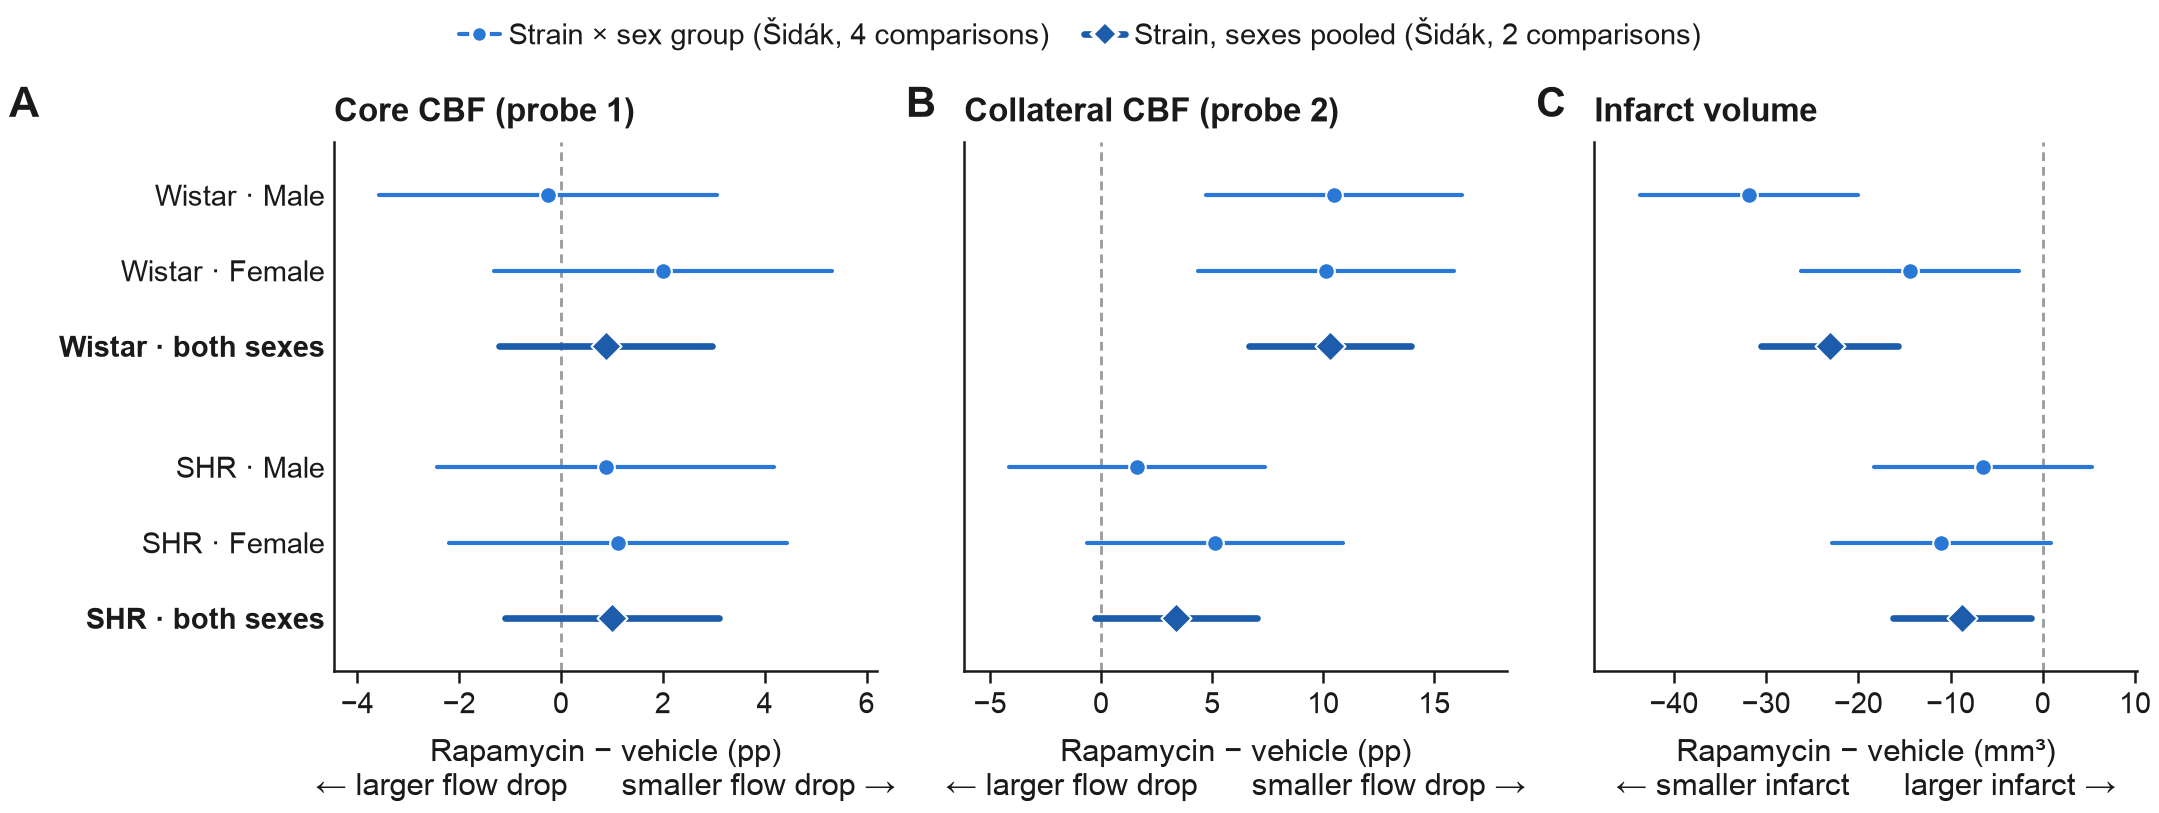

In [21]:
fig = pl.figure_forest(effects)
pl.save(fig, FIG_DIR, "fig06_rapamycin_effects")
plt.show()

**Figure 6.** Rapamycin minus vehicle, with Šidák-adjusted 95 % simultaneous CIs. Dots are strain × sex groups; diamonds pool both sexes within a strain. An interval that does not cross the dashed zero line marks a significant difference.

> **Interpretation**
>
> - Rapamycin reduced infarct volume in both strains, by 23.1 mm³ (31 %) in Wistar and by 8.8 mm³ (11 %) in SHR. Within groups it was clear in Wistar males (−31.9 mm³, −41 %) and Wistar females (−14.4 mm³, −20 %); in SHR neither sex reached significance on its own (males −6.5 mm³, females −11.0 mm³).
> - In Wistar, treated rats lost about 10 pp less collateral flow than vehicle rats, in both sexes. In SHR the difference was small (+3.4 pp, sexes pooled) and not significant. Whether this is a drug effect depends on when CBF was recorded (§ 2).
> - Core CBF showed no detectable treatment difference in any group: every interval includes zero.
> - The SHR males' interval runs from −18.3 to +5.3 mm³, which includes both no effect and a moderate benefit, as § 4.1 predicts for a single group.
> - The % intervals divide the difference's CI by the vehicle mean and ignore that mean's own uncertainty, so they are approximate.

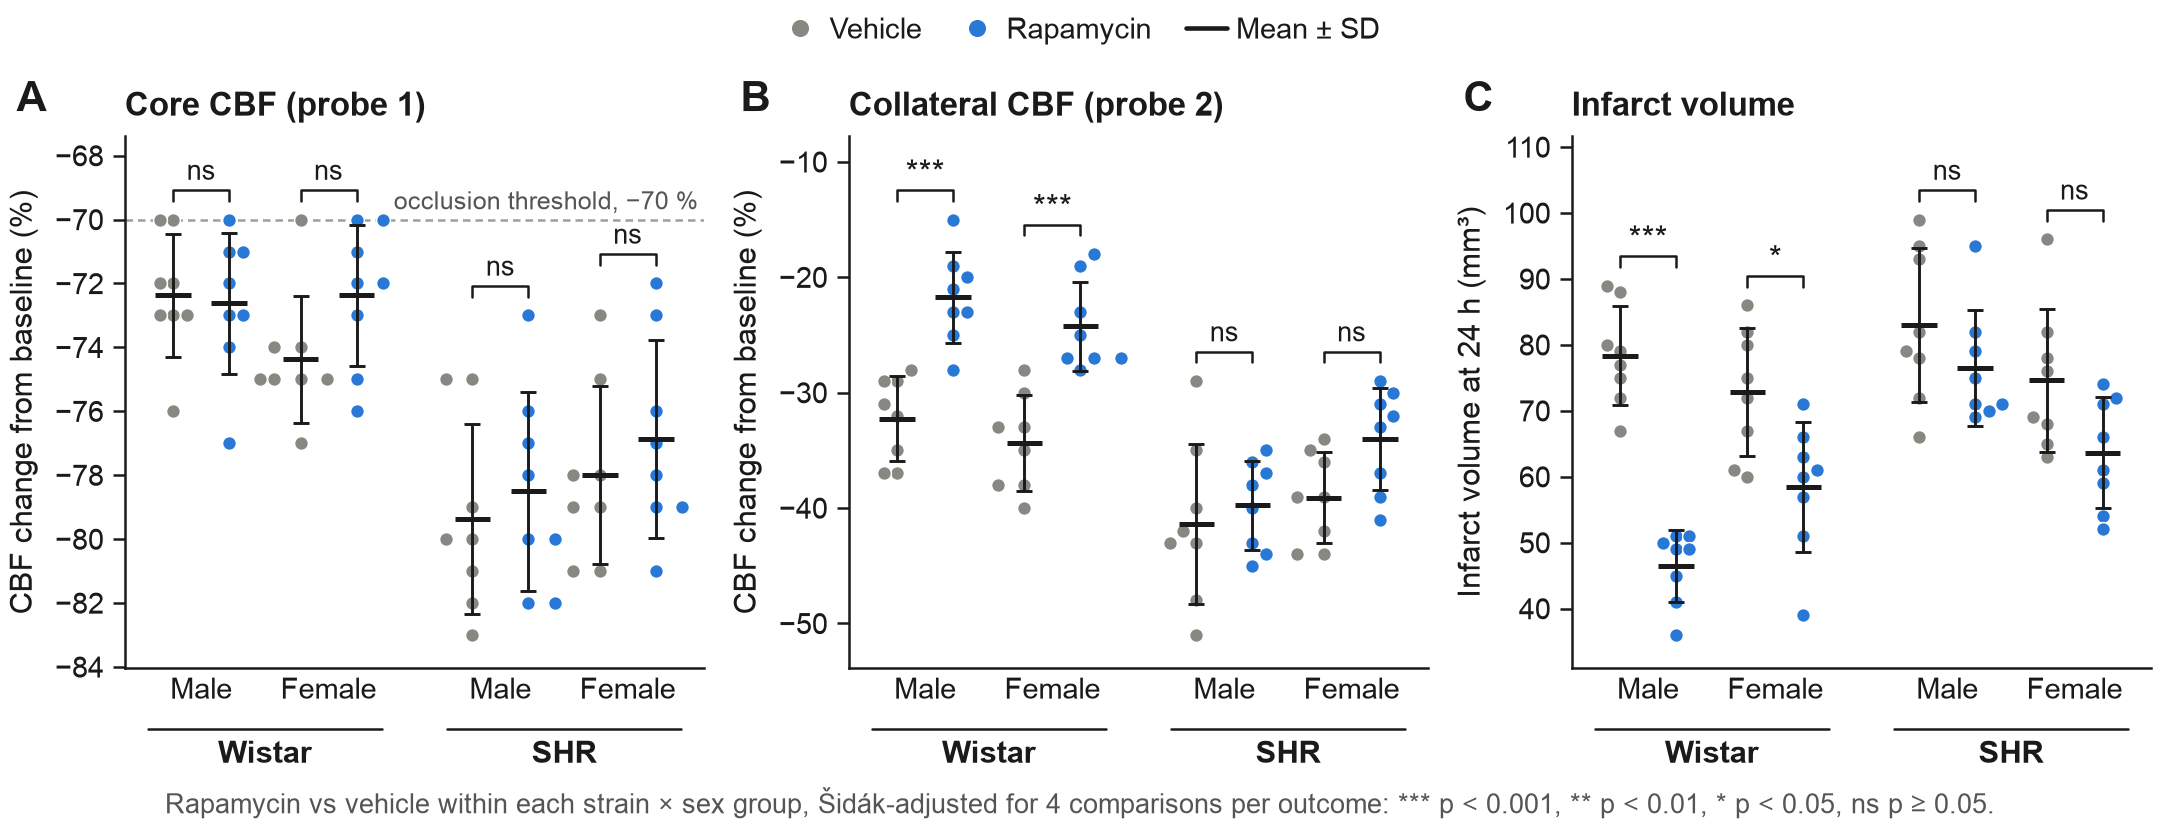

In [22]:
subgroup_effects = {c: e[e["family"] == "By strain × sex"] for c, e in effects.items()}
fig = pl.figure_individuals(data, subgroup_effects,
                            note="Rapamycin vs vehicle within each strain × sex group, Šidák-adjusted for 4 comparisons "
                                 "per outcome: *** p < 0.001, ** p < 0.01, * p < 0.05, ns p ≥ 0.05.")
pl.save(fig, FIG_DIR, "fig07_individual_animals_with_tests")
plt.show()

**Figure 7.** Figure 1 with Šidák-adjusted significance for rapamycin versus vehicle in each strain × sex group (4 comparisons per outcome): *** p < 0.001, ** p < 0.01, * p < 0.05, ns not significant. Exact p-values are in the § 8.1 tables.

### 8.2 Collateral versus core probe

| Question | Method | Rationale |
|---|---|---|
| Did the treatment groups differ more in collateral flow than in core flow? | Rapamycin − vehicle on each animal's probe 2 − probe 1 difference: overall (from the three-way ANOVA) and within each strain (Šidák, 2) | Finding a difference at one probe and none at the other is not a test of a difference between them (Nieuwenhuis et al. 2011). Testing the within-animal difference answers the question directly |

In [23]:
gap_data = data.assign(probe_gap_pp=data["cbf_probe2_pct"] - data["cbf_probe1_pct"])
gap_overall = st.anova_table(gap_data, "probe_gap_pp").set_index("term").loc["Treatment"]
gap_by_strain = st.rapamycin_effects(gap_data, "probe_gap_pp").query("family == 'By strain (sexes pooled)'")
rows = [{"Comparison": "Both strains (ANOVA main effect)",
         "Rapamycin − vehicle on probe 2 − probe 1 [95 % CI]": f"{rp.est_ci(gap_overall['estimate'], gap_overall['ci_low'], gap_overall['ci_high'])} pp",
         "p": rp.fmt_p(gap_overall["p"]), "Verdict": "clear" if gap_overall["p_holm"] < ALPHA else "not significant"}]
rows += [{"Comparison": f"{r['strain']} (Šidák, 2; simultaneous CI)",
          "Rapamycin − vehicle on probe 2 − probe 1 [95 % CI]": f"{rp.est_ci(r['estimate'], r['ci_low'], r['ci_high'])} pp",
          "p": rp.fmt_p(r["p_sidak"]), "Verdict": "clear" if r["p_sidak"] < ALPHA else "not significant"}
         for _, r in gap_by_strain.iterrows()]
rp.table(pd.DataFrame(rows), caption="Rapamycin − vehicle on the within-animal difference between the probes (probe 2 − probe 1)", emphasis="Verdict",
         right=["Rapamycin − vehicle on probe 2 − probe 1 [95 % CI]", "p"])

Comparison,Rapamycin − vehicle on probe 2 − probe 1 [95 % CI],p,Verdict
Both strains (ANOVA main effect),"+5.9 [3.4, 8.4] pp",< 0.001,clear
"Wistar (Šidák, 2; simultaneous CI)","+9.4 [5.4, 13.5] pp",< 0.001,clear
"SHR (Šidák, 2; simultaneous CI)","+2.4 [−1.7, 6.4] pp",0.333,not significant


> **Interpretation**
>
> The treatment difference was 5.9 pp larger at the collateral probe than at the core probe (95 % CI 3.4 to 8.4, p < 0.001). It came from Wistar (+9.4 pp); in SHR it was small and not significant (+2.4 pp). If CBF was recorded after dosing (§ 2), this pattern is consistent with the original study, in which rapamycin acted on the collateral vessels.

## 9. Pairwise comparisons of all groups (Tukey HSD)

| Question | Method | Rationale |
|---|---|---|
| Q3: which specific groups differ from each other? | Tukey's honestly significant difference test over all 28 pairs of the 8 groups, per outcome | Keeps the chance of any false positive across all 28 comparisons at 5 %. This is the most detailed view and supplements § 7–8, which answer the scientific questions more directly |

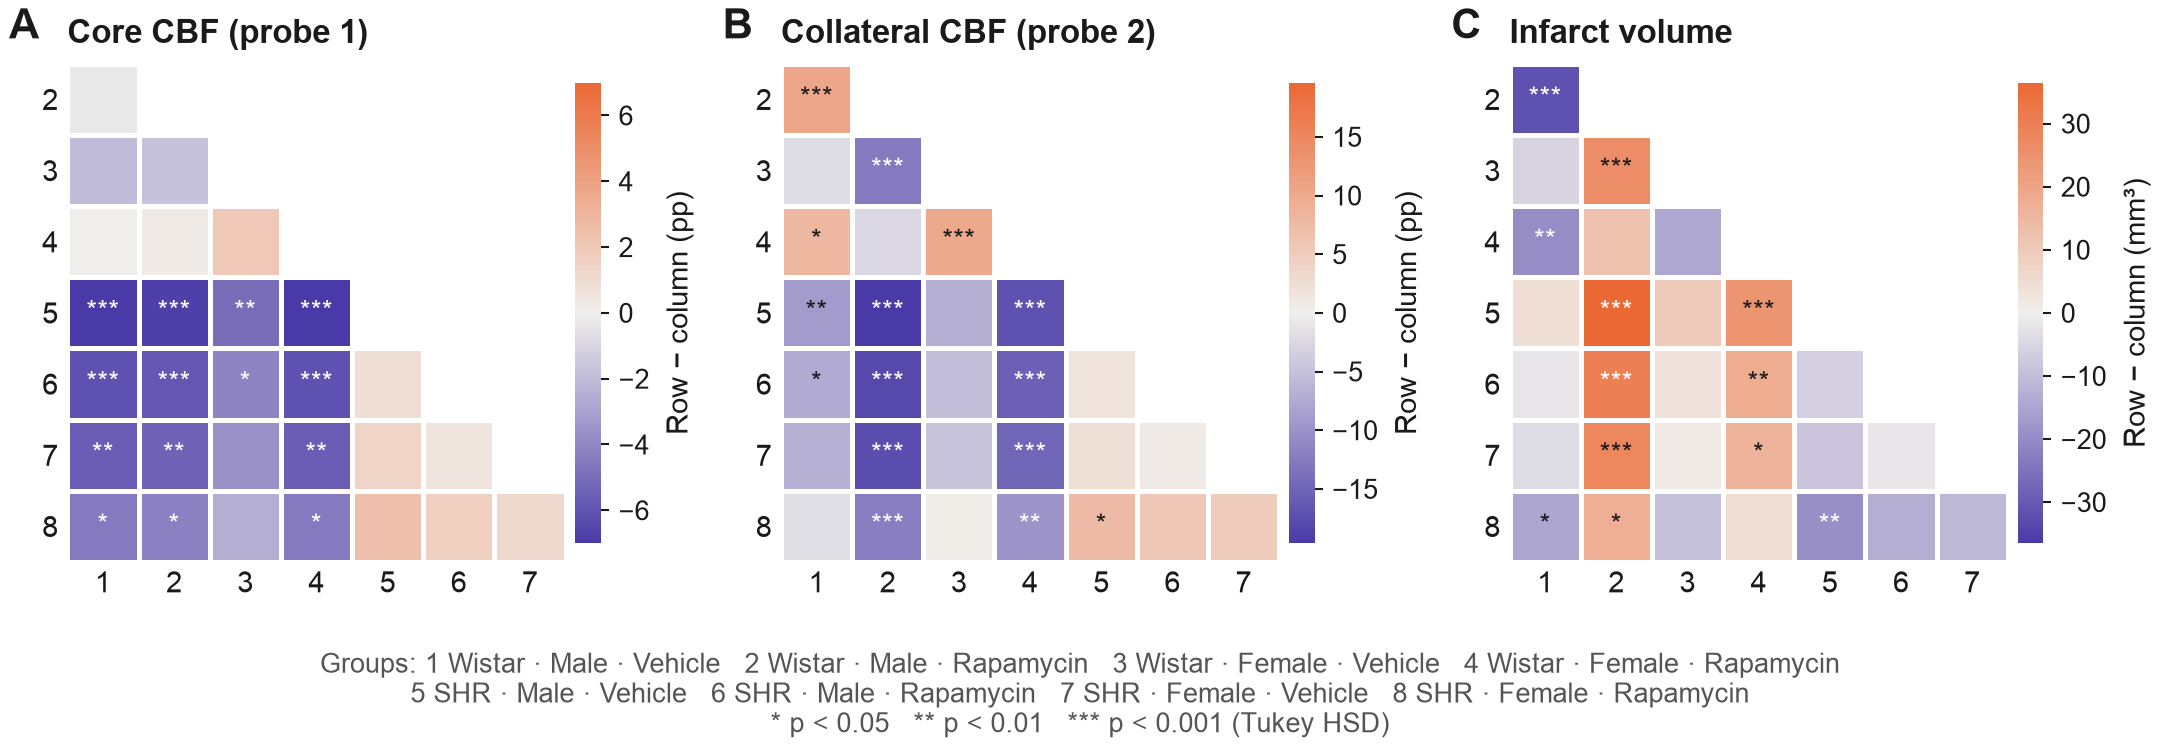

In [24]:
tukey = {o.column: st.tukey_all_pairs(data, o.column) for o in OUTCOMES}
fig = pl.figure_tukey(tukey)
pl.save(fig, FIG_DIR, "fig08_tukey_all_pairs")
plt.show()

**Figure 8.** Each cell compares the group in its row with the group in its column (row − column); the key to the group numbers is below the panels. Violet means the row group is lower, orange that it is higher. Stars mark Tukey-adjusted significance.

In [25]:
pairs = []
for (i, row_group), (j, col_group) in [((i, a), (j, b)) for i, a in enumerate(dz.GROUP_LABELS)
                                       for j, b in enumerate(dz.GROUP_LABELS) if i > j]:
    entry = {"Pair (row − column)": f"{i + 1} − {j + 1}", "Groups": f"{row_group}  vs  {col_group}"}
    for o in OUTCOMES:
        t = tukey[o.column]
        hit = t[((t["group_1"] == col_group) & (t["group_2"] == row_group)) |
                ((t["group_1"] == row_group) & (t["group_2"] == col_group))].iloc[0]
        diff = hit["difference"] if hit["group_2"] == row_group else -hit["difference"]
        entry[f"{o.name}: difference"] = rp.signed(diff)
        entry[f"{o.name}: p"] = rp.fmt_p(hit["p_tukey"])
    pairs.append(entry)
pairs = pd.DataFrame(pairs)
pairs.to_csv(TABLE_DIR / "tableS1_tukey_all_pairs.csv", index=False)

n_sig = {o.name: int((tukey[o.column]["p_tukey"] < ALPHA).sum()) for o in OUTCOMES}
display(Markdown("Significant pairs out of 28: " + ", ".join(f"{k} {v}" for k, v in n_sig.items()) + "."))
pairs_view = pairs.copy()
pairs_view.columns = pd.MultiIndex.from_tuples([("", "Pair"), ("", "Groups (row vs column)")]
                                               + [(o.name, stat) for o in OUTCOMES for stat in ("Difference", "p")])
label_col = ("", "Groups (row vs column)")
pairs_view[label_col] = pairs_view[label_col].str.replace(" · ", "\u00a0·\u00a0")  # lines break only around "vs"
rp.table(pairs_view, caption="All 28 pairwise differences (row − column) with Tukey-adjusted p-values",
         right=[c for c in pairs_view.columns if c[0]])

Significant pairs out of 28: Core CBF (probe 1) 14, Collateral CBF (probe 2) 15, Infarct volume 12.

> **Interpretation**
>
> Most significant pairs set SHR against Wistar, or a Wistar rapamycin group against a vehicle group: the same picture as § 7–8. Because Tukey covers all 28 pairs it is more conservative than the planned comparisons, and § 8 remains the guide to where rapamycin works.

## 10. Robustness checks

| Question | Method | Rationale |
|---|---|---|
| Would a different but defensible analysis change any conclusion? | Re-run the analysis (a) with HC3 standard errors; (b) without the six animals at exactly −70 % core flow (the strict "> 70 %" criterion, n = 58); (c) for the ANOVA, with Holm correction across all 21 tests of the three outcomes instead of within each outcome. Then compare every verdict | (a) guards against unequal variances, which a variance test cannot rule out with 8 animals per group; (b) settles the ambiguous occlusion criterion; (c) shows how much depends on how the tests are grouped. A conclusion that flips under any of them is fragile |

In [26]:
strict = data[data["meets_strict_occlusion"]]
print(f"Strict-criterion subset: {len(strict)} animals.")
display(rp.table(strict.groupby("group", observed=True).size().rename("n").reset_index()
                 .rename(columns={"group": "Group"}), caption="Group sizes under the strict criterion", right=["n"]))

variants = {"Primary (n = 64)": (data, None), "Robust HC3 (n = 64)": (data, "hc3"), "Strict exclusion (n = 58)": (strict, None)}
p_by = {o.column: {name: st.anova_pvalues(d, o.column, robust=r) for name, (d, r) in variants.items()} for o in OUTCOMES}
# Stricter multiplicity: one Holm correction over all 21 ANOVA tests of the three outcomes.
primary_all = np.concatenate([p_by[o.column]["Primary (n = 64)"].to_numpy() for o in OUTCOMES])
holm_all = st.holm(primary_all).reshape(len(OUTCOMES), -1)

anova_rows = []
for k, o in enumerate(OUTCOMES):
    p = p_by[o.column]
    verdict = {name: st.classify(v, st.holm(v)) for name, v in p.items()}
    verdict["Holm over 21 tests"] = st.classify(p["Primary (n = 64)"], holm_all[k])
    for i, term in enumerate(dz.TERM_ORDER):
        row = {"Outcome": o.name, "Term": term}
        row.update({name: f"{rp.fmt_p(p[name].iloc[i])} · {verdict[name][i]}" for name in variants})
        row["Holm over 21 tests"] = f"{rp.fmt_p(holm_all[k][i])} · {verdict['Holm over 21 tests'][i]}"
        row["Verdict"] = "unchanged" if len({v[i] for v in verdict.values()}) == 1 else "changed"
        anova_rows.append(row)
anova_robust = pd.DataFrame(anova_rows)
anova_robust.to_csv(TABLE_DIR / "table5_robustness_anova.csv", index=False)
rp.table(anova_robust, caption="ANOVA: p-value and verdict under each analysis (first three columns: unadjusted p with the "
                               "verdict from Holm within each ANOVA; last column: Holm p over all 21 tests)",
         right=[*variants, "Holm over 21 tests"], emphasis="Verdict")

Strict-criterion subset: 58 animals.


Group,n
Wistar · Male · Vehicle,6
Wistar · Male · Rapamycin,7
Wistar · Female · Vehicle,7
Wistar · Female · Rapamycin,6
SHR · Male · Vehicle,8
SHR · Male · Rapamycin,8
SHR · Female · Vehicle,8
SHR · Female · Rapamycin,8


Outcome,Term,Primary (n = 64),Robust HC3 (n = 64),Strict exclusion (n = 58),Holm over 21 tests,Verdict
Core CBF (probe 1),Strain,< 0.001 · clear,< 0.001 · clear,< 0.001 · clear,< 0.001 · clear,unchanged
Core CBF (probe 1),Sex,0.630 · not significant,0.652 · not significant,0.707 · not significant,1.000 · not significant,unchanged
Core CBF (probe 1),Treatment,0.151 · not significant,0.179 · not significant,0.137 · not significant,1.000 · not significant,unchanged
Core CBF (probe 1),Strain × Sex,0.071 · not significant,0.090 · not significant,0.064 · not significant,0.778 · not significant,unchanged
Core CBF (probe 1),Strain × Treatment,0.923 · not significant,0.928 · not significant,1.000 · not significant,1.000 · not significant,unchanged
Core CBF (probe 1),Sex × Treatment,0.336 · not significant,0.368 · not significant,0.472 · not significant,1.000 · not significant,unchanged
Core CBF (probe 1),Strain × Sex × Treatment,0.441 · not significant,0.471 · not significant,0.595 · not significant,1.000 · not significant,unchanged
Collateral CBF (probe 2),Strain,< 0.001 · clear,< 0.001 · clear,< 0.001 · clear,< 0.001 · clear,unchanged
Collateral CBF (probe 2),Sex,0.453 · not significant,0.483 · not significant,0.322 · not significant,1.000 · not significant,unchanged
Collateral CBF (probe 2),Treatment,< 0.001 · clear,< 0.001 · clear,< 0.001 · clear,< 0.001 · clear,unchanged


In [27]:
robust_effects = {o.column: st.rapamycin_effects(data, o.column, relative=o.relative, variance="hc3") for o in OUTCOMES}
strict_effects = {o.column: st.rapamycin_effects(strict, o.column, relative=o.relative) for o in OUTCOMES}
effect_rows = []
for o in OUTCOMES:
    for (_, a), (_, h), (_, b) in zip(effects[o.column].iterrows(), robust_effects[o.column].iterrows(),
                                      strict_effects[o.column].iterrows()):
        same = len({x["p_sidak"] < ALPHA for x in (a, h, b)}) == 1
        effect_rows.append({
            "Outcome": o.name,
            "Comparison": f"{a['strain']} · {a['sex'].lower() if a['sex'] == 'Both sexes' else a['sex']}",
            "Primary: difference, p": f"{rp.signed(a['estimate'])}, p {rp.fmt_p(a['p_sidak'])}",
            "HC3 (group-specific variances): p": f"p {rp.fmt_p(h['p_sidak'])}",
            "Strict exclusion: difference, p": f"{rp.signed(b['estimate'])}, p {rp.fmt_p(b['p_sidak'])}",
            "Verdict": "unchanged" if same else "changed",
        })
effect_robust = pd.DataFrame(effect_rows)
effect_robust.to_csv(TABLE_DIR / "table6_robustness_rapamycin.csv", index=False)

n_changed = (anova_robust["Verdict"] == "changed").sum() + (effect_robust["Verdict"] == "changed").sum()
display(Markdown(f"{len(anova_robust) + len(effect_robust) - n_changed} of {len(anova_robust) + len(effect_robust)} verdicts are unchanged. "
                 "Changed: " + (", ".join(anova_robust.loc[anova_robust['Verdict'] == 'changed', ['Outcome', 'Term']]
                                          .agg(' / '.join, axis=1)) or "none") + "."))
rp.table(effect_robust, caption="Rapamycin − vehicle (Šidák p): shared variance, group-specific variances, and without the six animals at −70 %",
         emphasis="Verdict")

37 of 39 verdicts are unchanged. Changed: Collateral CBF (probe 2) / Strain × Sex, Infarct volume / Strain × Sex.

Outcome,Comparison,"Primary: difference, p",HC3 (group-specific variances): p,"Strict exclusion: difference, p",Verdict
Core CBF (probe 1),Wistar · both sexes,"+0.9, p 0.566",p 0.469,"+1.0, p 0.530",unchanged
Core CBF (probe 1),SHR · both sexes,"+1.0, p 0.478",p 0.616,"+1.0, p 0.457",unchanged
Core CBF (probe 1),Wistar · Male,"−0.2, p 0.999",p 0.999,"+0.2, p 1.000",unchanged
Core CBF (probe 1),Wistar · Female,"+2.0, p 0.418",p 0.284,"+1.8, p 0.577",unchanged
Core CBF (probe 1),SHR · Male,"+0.9, p 0.938",p 0.973,"+0.9, p 0.931",unchanged
Core CBF (probe 1),SHR · Female,"+1.1, p 0.858",p 0.925,"+1.1, p 0.845",unchanged
Collateral CBF (probe 2),Wistar · both sexes,"+10.3, p < 0.001",p < 0.001,"+10.4, p < 0.001",unchanged
Collateral CBF (probe 2),SHR · both sexes,"+3.4, p 0.073",p 0.148,"+3.4, p 0.082",unchanged
Collateral CBF (probe 2),Wistar · Male,"+10.5, p < 0.001",p < 0.001,"+10.8, p < 0.001",unchanged
Collateral CBF (probe 2),Wistar · Female,"+10.1, p < 0.001",p < 0.001,"+10.1, p < 0.001",unchanged


> **Interpretation**
>
> - Treatment and strain × treatment keep their verdicts under HC3, under the strict exclusion and under Holm across all 21 ANOVA tests (strain × treatment p = 0.045 there).
> - All 18 rapamycin comparisons keep their verdicts, but the SHR infarct reduction is borderline: its Šidák p is 0.019 with the shared variance, 0.049 with group-specific variances and 0.027 without the six animals at −70 %. SHR groups vary more than Wistar groups, so the shared variance makes the SHR comparisons look slightly more precise than they are. The SHR infarct reduction is best described as modest and of uncertain size.
> - Strain × sex drops from clear to suggestive under both the strict exclusion and the 21-test correction. It is a lead for future work.

## 11. Exploratory analysis: CBF and infarct volume

| Question | Method | Rationale |
|---|---|---|
| Q4: do animals with better blood flow have smaller infarcts? | Pearson correlation between each probe and infarct volume: (a) across all animals and (b) within groups, after removing each group's mean from both variables | Across all animals, groups that differ in both CBF and infarct (e.g. SHR vs Wistar) create a correlation even if individual animals show none. The within-group correlation isolates the animal-level link |

In the original study, blood flow after reperfusion predicted infarct size in Wistar rats; this section asks the nearest question the dataset allows.

CBF measure,Correlation,r [95 % CI],df,p
Core CBF (probe 1),Overall (all 64 animals),"−0.35 [−0.55, −0.12]",62,0.004
Core CBF (probe 1),Within groups (group means removed),"0.00 [−0.26, 0.26]",55,0.987
Collateral CBF (probe 2),Overall (all 64 animals),"−0.65 [−0.77, −0.48]",62,< 0.001
Collateral CBF (probe 2),Within groups (group means removed),"−0.14 [−0.39, 0.12]",55,0.282


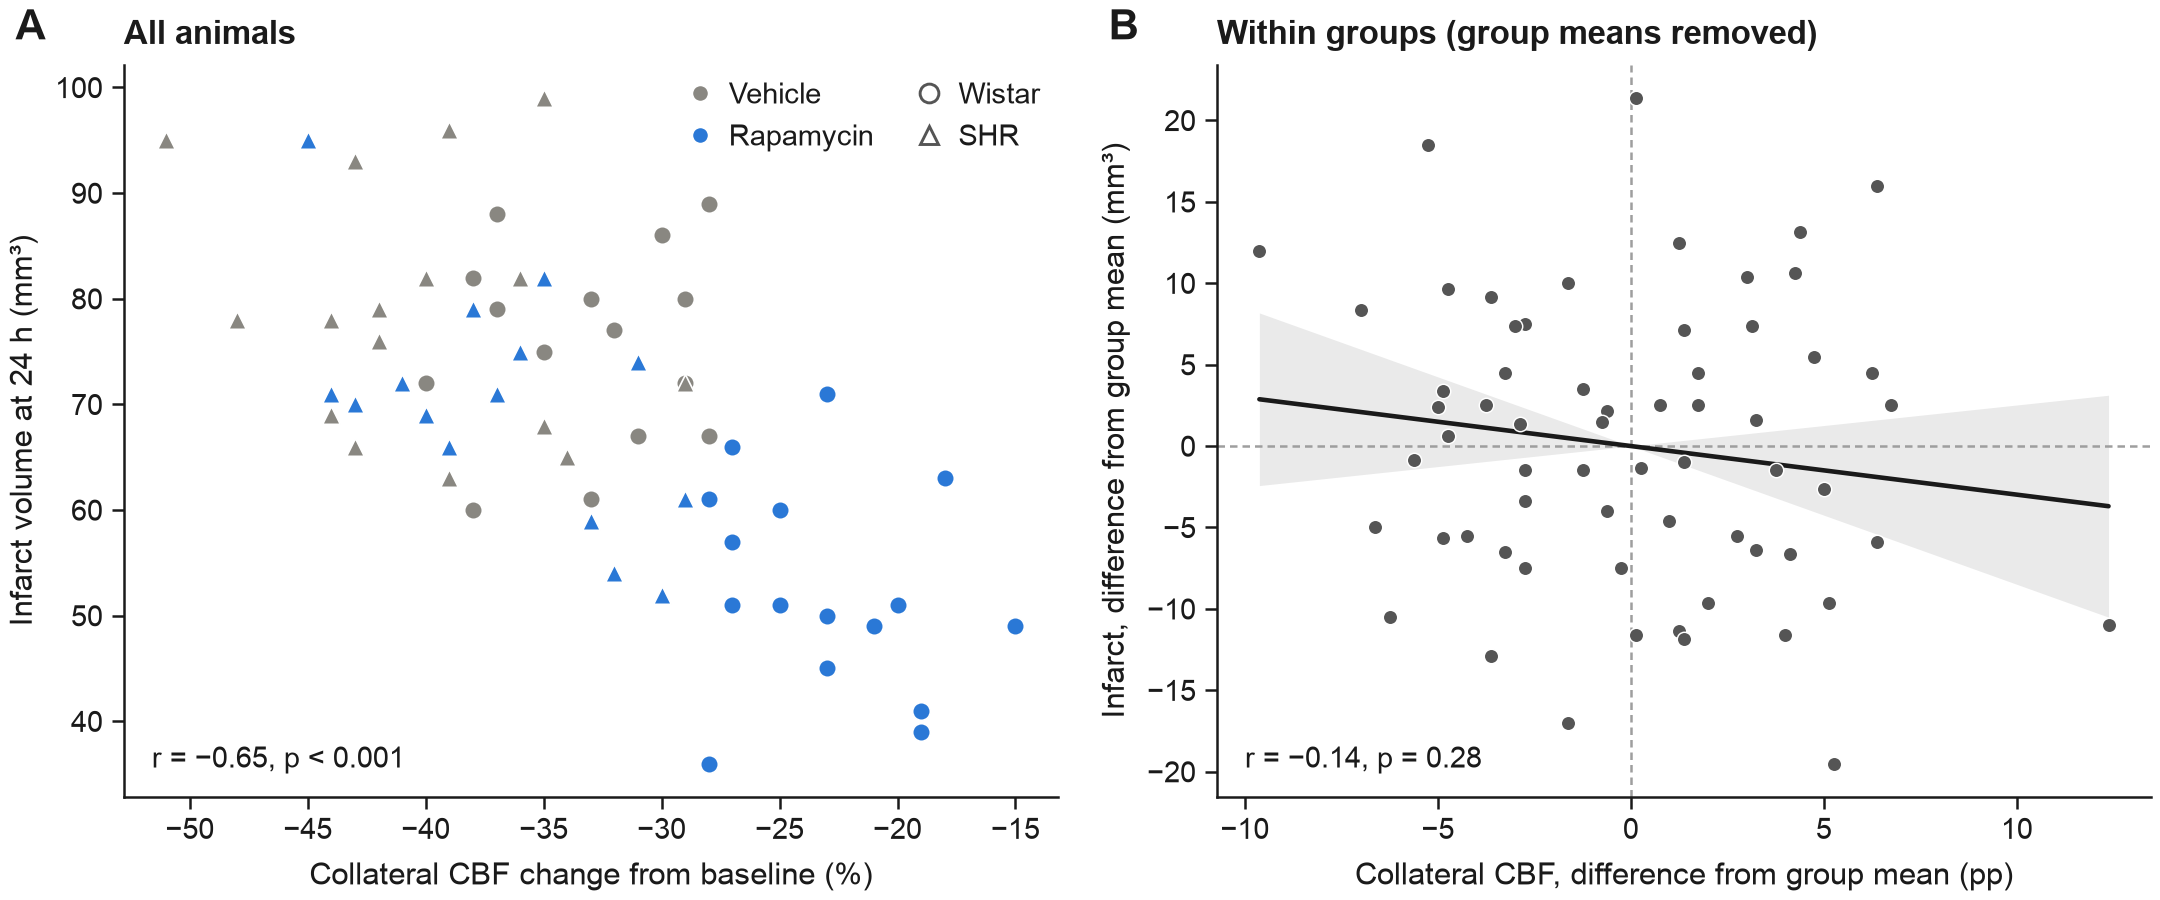

In [28]:
correlations = pd.concat([st.correlation_summary(data, x, "infarct_mm3") for x in ("cbf_probe1_pct", "cbf_probe2_pct")],
                         ignore_index=True)
correlations.to_csv(TABLE_DIR / "table7_cbf_infarct_correlations.csv", index=False)
display(rp.table(pd.DataFrame({
    "CBF measure": correlations["x"].map(lambda c: OUTCOME_BY_COLUMN[c].name),
    "Correlation": correlations["type"],
    "r [95 % CI]": [f"{rp.num(r, 2)} {rp.ci(lo, hi)}" for r, lo, hi in zip(correlations["r"], correlations["ci_low"], correlations["ci_high"])],
    "df": correlations["df"],
    "p": correlations["p"].map(rp.fmt_p),
}), caption="Correlation of each CBF measure with infarct volume", right=["r [95 % CI]", "df", "p"]))

fig = pl.figure_cbf_infarct(data, correlations[correlations["x"] == "cbf_probe2_pct"])
pl.save(fig, FIG_DIR, "fig09_cbf_vs_infarct")
plt.show()

**Figure 9.** A: every animal, coloured by treatment, with circles for Wistar and triangles for SHR. B: the same animals after subtracting each group's mean from both variables, which leaves only differences between animals within a group. The line is the pooled within-group regression, with its 95 % CI shaded.

> **Interpretation**
>
> Across all animals, collateral CBF and infarct volume are strongly correlated (r = −0.65). Within groups the link is weak and not significant (r = −0.14, 95 % CI −0.39 to 0.12; p = 0.28). The overall correlation mainly reflects that the groups with better collateral flow (Wistar, rapamycin) also had smaller infarcts; whether an individual animal with better flow does better cannot be settled with 8 animals per group. Core CBF shows the same pattern: r = −0.35 overall and zero within groups.

## 12. Discussion

### 12.1 Comparison with the original study

Beard et al. (2020) studied young males only and measured SHR infarcts at 4 h. The comparison below is between studies, not a within-study test of age.

In [29]:
e = effects["infarct_mm3"].set_index(["strain", "sex"])
c = effects["cbf_probe2_pct"].set_index(["strain", "sex"])

def ours(strain, sex):
    r = e.loc[(strain, sex)]
    return f"{rp.num(r['vehicle_mean'])} → {rp.num(r['rapamycin_mean'])} mm³ ({rp.signed(r['pct_of_vehicle'], 0)} %)"

comparison = pd.DataFrame([
    ("Wistar infarct, males", "62.7 → 35.7 mm³ (−43 %) at 24 h", ours("Wistar", "Male")),
    ("Wistar infarct, females", "not studied", ours("Wistar", "Female")),
    ("SHR infarct, males", "76.4 → 76.3 mm³ (no detectable difference) at 4 h", ours("SHR", "Male")),
    ("SHR infarct, females", "not studied", ours("SHR", "Female")),
    ("Collateral flow, Wistar", "+43 % vs the pre-dose level",
     f"flow drop {rp.num(abs(c.loc[('Wistar', 'Both sexes'), 'estimate']))} pp smaller"),
    ("Collateral flow, SHR", "+32 % vs the pre-dose level (vs vehicle: not significant)",
     f"flow drop {rp.num(abs(c.loc[('SHR', 'Both sexes'), 'estimate']))} pp smaller (not significant)"),
], columns=["Measure", "Beard et al. 2020: young males", "This study: aged rats (infarct at 24 h)"])
rp.table(comparison, caption="Rapamycin effects in the original study and in this study (vehicle → rapamycin)")

Measure,Beard et al. 2020: young males,This study: aged rats (infarct at 24 h)
"Wistar infarct, males",62.7 → 35.7 mm³ (−43 %) at 24 h,78.4 → 46.5 mm³ (−41 %)
"Wistar infarct, females",not studied,72.9 → 58.5 mm³ (−20 %)
"SHR infarct, males",76.4 → 76.3 mm³ (no detectable difference) at 4 h,83.0 → 76.5 mm³ (−8 %)
"SHR infarct, females",not studied,74.6 → 63.6 mm³ (−15 %)
"Collateral flow, Wistar",+43 % vs the pre-dose level,flow drop 10.3 pp smaller
"Collateral flow, SHR",+32 % vs the pre-dose level (vs vehicle: not significant),flow drop 3.4 pp smaller (not significant)


> **Interpretation**
>
> - In aged Wistar males the relative infarct reduction (−41 %) matches that in the original young males (−43 %).
> - The original authors predicted a larger collateral response in aged SHR, because the collaterals of aged SHR appear to regain sensitivity to nitric oxide. In our aged SHR the collateral difference was small and not significant (+3.4 pp), so, if CBF was recorded after dosing (§ 2), the data give no support for that prediction. The collateral measures differ between the studies (the original measured the change after dosing relative to the pre-dose level), so this comparison is qualitative.
> - For infarct volume, aged SHR showed a modest reduction at 24 h. Young SHR in the original showed no detectable reduction, but that was measured at 4 h.

### 12.2 Limitations

| Limitation | Consequence |
|---|---|
| The timing of the CBF measurement relative to dosing is not documented | The pattern here, no treatment difference in core flow and a clear one in collateral flow, is what the original mechanism predicts for recordings after dosing, and a collateral difference this large (p < 0.001) would be very unlikely by chance before dosing. The dataset still cannot confirm the timing (§ 2) |
| Core CBF is bounded by the occlusion criterion | Core CBF describes animals selected on that variable (§ 6) |
| Group variances differ somewhat between the strains | With group-specific variances the SHR infarct reduction is borderline (§ 10) |
| No primary outcome was registered in advance | Multiplicity is controlled within each outcome only; under one correction across all 21 ANOVA tests, strain × sex would no longer be significant (§ 10) |
| One value per probe; no time course and no reperfusion CBF | The original study's strongest predictor of infarct size, flow after reperfusion, is not available |
| One infarct timepoint (24 h) and no functional outcome | Whether smaller infarcts meant better function is unknown |
| 8 animals per group | Single-group effects are imprecise and the three-way interaction is underpowered (§ 4.1); non-significant subgroup results are inconclusive, not negative |
| Aged animals only | Age cannot be tested within this study |
| The dataset reports no exclusions or deaths | If animals were lost before 24 h, the results describe survivors only (ARRIVE 2.0 asks for exclusions to be reported; Percie du Sert et al. 2020) |

## 13. Verification

The run stops here if any check fails. The first check recomputes the key numbers quoted in the text, so text and results cannot drift apart unnoticed; the others re-derive key results by an independent route.

In [30]:
A = {c: t.set_index("term") for c, t in anova_tables.items()}
R = {c: t.set_index(["strain", "sex"]) for c, t in effects.items()}
S = {c: t.set_index("within") for c, t in sex_effects.items()}
T = {c: t.set_index("within") for c, t in strain_effects.items()}
H = {c: t.set_index(["strain", "sex"]) for c, t in robust_effects.items()}
X = {c: t.set_index(["strain", "sex"]) for c, t in strict_effects.items()}
G = gap_by_strain.set_index("strain")
wistar_core = data.loc[data["strain"] == "Wistar", "cbf_probe1_pct"]
means_by_treatment = data.groupby("treatment", observed=True)["infarct_mm3"].mean()
corr2 = correlations[correlations["x"] == "cbf_probe2_pct"].set_index("type")
corr1 = correlations[correlations["x"] == "cbf_probe1_pct"].set_index("type")

# (description, computed value, value quoted in the text, decimals)
quoted = [
    ("Infarct, vehicle mean", means_by_treatment["Vehicle"], 77.2, 1),
    ("Infarct, rapamycin mean", means_by_treatment["Rapamycin"], 61.3, 1),
    ("Infarct, rapamycin main effect (mm³)", A["infarct_mm3"].loc["Treatment", "estimate"], -15.9, 1),
    ("Infarct, rapamycin main effect (% of vehicle)", 100 * A["infarct_mm3"].loc["Treatment", "estimate"] / means_by_treatment["Vehicle"], -21, 0),
    ("Infarct, treatment partial η²", A["infarct_mm3"].loc["Treatment", "partial_eta_sq"], 0.46, 2),
    ("Infarct, strain effect (mm³)", A["infarct_mm3"].loc["Strain", "estimate"], 10.4, 1),
    ("Infarct, strain × treatment (mm³)", A["infarct_mm3"].loc["Strain × Treatment", "estimate"], 14.4, 1),
    ("Infarct, strain × treatment p", A["infarct_mm3"].loc["Strain × Treatment", "p"], 0.003, 3),
    ("Infarct, sex × treatment p", A["infarct_mm3"].loc["Sex × Treatment", "p"], 0.16, 2),
    ("Infarct, three-way p", A["infarct_mm3"].loc["Strain × Sex × Treatment", "p"], 0.020, 3),
    ("Infarct, three-way Holm p", A["infarct_mm3"].loc["Strain × Sex × Treatment", "p_holm"], 0.061, 3),
    ("Infarct, Wistar effect (mm³)", R["infarct_mm3"].loc[("Wistar", "Both sexes"), "estimate"], -23.1, 1),
    ("Infarct, Wistar effect (%)", R["infarct_mm3"].loc[("Wistar", "Both sexes"), "pct_of_vehicle"], -31, 0),
    ("Infarct, SHR effect (mm³)", R["infarct_mm3"].loc[("SHR", "Both sexes"), "estimate"], -8.8, 1),
    ("Infarct, SHR effect (%)", R["infarct_mm3"].loc[("SHR", "Both sexes"), "pct_of_vehicle"], -11, 0),
    ("Infarct, Wistar male effect (mm³)", R["infarct_mm3"].loc[("Wistar", "Male"), "estimate"], -31.9, 1),
    ("Infarct, Wistar male effect (%)", R["infarct_mm3"].loc[("Wistar", "Male"), "pct_of_vehicle"], -41, 0),
    ("Infarct, Wistar female effect (mm³)", R["infarct_mm3"].loc[("Wistar", "Female"), "estimate"], -14.4, 1),
    ("Infarct, Wistar female effect (%)", R["infarct_mm3"].loc[("Wistar", "Female"), "pct_of_vehicle"], -20, 0),
    ("Infarct, SHR male effect (mm³)", R["infarct_mm3"].loc[("SHR", "Male"), "estimate"], -6.5, 1),
    ("Infarct, SHR female effect (mm³)", R["infarct_mm3"].loc[("SHR", "Female"), "estimate"], -11.0, 1),
    ("Infarct, SHR male CI low", R["infarct_mm3"].loc[("SHR", "Male"), "ci_low"], -18.3, 1),
    ("Infarct, SHR male CI high", R["infarct_mm3"].loc[("SHR", "Male"), "ci_high"], 5.3, 1),
    ("Infarct, SHR female − male (mm³)", S["infarct_mm3"].loc["SHR", "estimate"], -10.6, 1),
    ("Collateral, SHR female − male (pp)", S["cbf_probe2_pct"].loc["SHR", "estimate"], 4.0, 1),
    ("Infarct, SHR effect, Šidák p", R["infarct_mm3"].loc[("SHR", "Both sexes"), "p_sidak"], 0.019, 3),
    ("Infarct, SHR effect, Šidák p with HC3", H["infarct_mm3"].loc[("SHR", "Both sexes"), "p_sidak"], 0.049, 3),
    ("Infarct, SHR effect, Šidák p under strict exclusion", X["infarct_mm3"].loc[("SHR", "Both sexes"), "p_sidak"], 0.027, 3),
    ("Infarct, SHR − Wistar among vehicle (mm³)", T["infarct_mm3"].loc["Vehicle", "estimate"], 3.2, 1),
    ("Infarct, SHR − Wistar among vehicle, Šidák p", T["infarct_mm3"].loc["Vehicle", "p_sidak"], 0.55, 2),
    ("Infarct, SHR − Wistar among rapamycin (mm³)", T["infarct_mm3"].loc["Rapamycin", "estimate"], 17.6, 1),
    ("Core, treatment main effect (pp)", A["cbf_probe1_pct"].loc["Treatment", "estimate"], 0.9, 1),
    ("Core, treatment CI low", A["cbf_probe1_pct"].loc["Treatment", "ci_low"], -0.4, 1),
    ("Core, treatment CI high", A["cbf_probe1_pct"].loc["Treatment", "ci_high"], 2.2, 1),
    ("Probe gap, rapamycin effect (pp)", gap_overall["estimate"], 5.9, 1),
    ("Probe gap, CI low", gap_overall["ci_low"], 3.4, 1),
    ("Probe gap, CI high", gap_overall["ci_high"], 8.4, 1),
    ("Probe gap, Wistar (pp)", G.loc["Wistar", "estimate"], 9.4, 1),
    ("Probe gap, SHR (pp)", G.loc["SHR", "estimate"], 2.4, 1),
    ("Strain × treatment on infarct, Holm over 21 tests", holm_all[[o.column for o in OUTCOMES].index("infarct_mm3")][4], 0.045, 3),
    ("Wistar core CBF, animals at −70", (wistar_core == -70).sum(), 6, 0),
    ("Wistar core CBF, animals at −71", (wistar_core == -71).sum(), 3, 0),
    ("Collateral, strain effect (pp)", A["cbf_probe2_pct"].loc["Strain", "estimate"], -10.4, 1),
    ("Collateral, rapamycin main effect (pp)", A["cbf_probe2_pct"].loc["Treatment", "estimate"], 6.8, 1),
    ("Collateral, strain × treatment (pp)", A["cbf_probe2_pct"].loc["Strain × Treatment", "estimate"], -6.9, 1),
    ("Collateral, Wistar effect (pp)", R["cbf_probe2_pct"].loc[("Wistar", "Both sexes"), "estimate"], 10.3, 1),
    ("Collateral, SHR effect (pp)", R["cbf_probe2_pct"].loc[("SHR", "Both sexes"), "estimate"], 3.4, 1),
    ("Core, strain effect (pp)", A["cbf_probe1_pct"].loc["Strain", "estimate"], -5.2, 1),
    ("Core, residual SD (pp)", np.sqrt(models["cbf_probe1_pct"].mse_resid), 2.6, 1),
    ("Probe 2 − probe 1, mean (pp)", gap.mean(), 42, 0),
    ("Collateral vs infarct, overall r", corr2.loc["Overall (all 64 animals)", "r"], -0.65, 2),
    ("Collateral vs infarct, within-group r", corr2.loc["Within groups (group means removed)", "r"], -0.14, 2),
    ("Collateral vs infarct, within-group p", corr2.loc["Within groups (group means removed)", "p"], 0.28, 2),
    ("Collateral vs infarct, within-group CI low", corr2.loc["Within groups (group means removed)", "ci_low"], -0.39, 2),
    ("Collateral vs infarct, within-group CI high", corr2.loc["Within groups (group means removed)", "ci_high"], 0.12, 2),
    ("Core vs infarct, overall r", corr1.loc["Overall (all 64 animals)", "r"], -0.35, 2),
    ("Core vs infarct, within-group r", corr1.loc["Within groups (group means removed)", "r"], 0.00, 2),
    ("Detectable effect, main effect (SD)", sensitivity["detectable_d"].iloc[0], 0.71, 2),
    ("Detectable effect, main effect (mm³)", sensitivity["detectable_d"].iloc[0] * resid_sd, 6.6, 1),
    ("Detectable effect, one strain × sex group (SD)", sensitivity["detectable_d"].iloc[4], 1.7, 1),
    ("Detectable effect, one strain × sex group (mm³)", sensitivity["detectable_d"].iloc[4] * resid_sd, 16, 0),
]
text_checks = pd.DataFrame(quoted, columns=["Quoted in the text", "computed", "quoted", "decimals"])
text_checks["ok"] = [round(float(v), d) == q or (d == 0 and abs(v - q) < 0.5 + 1e-9)
                     for v, q, d in zip(text_checks["computed"], text_checks["quoted"], text_checks["decimals"])]

In [31]:
def check_f_equals_t_squared():
    for o in OUTCOMES:
        table = anova_tables[o.column]
        for key, (label, _) in dz.TERMS.items():
            row = table.set_index("term").loc[label]
            c = st.contrast(data, o.column, st.term_weights(key), models[o.column].mse_resid, models[o.column].df_resid)
            if not np.isclose(c["t"] ** 2, row["F"]):
                return False
    return True

def check_mse_is_pooled_variance():
    return all(np.isclose(models[o.column].mse_resid, data.groupby("group", observed=True)[o.column].var().mean())
               for o in OUTCOMES)

def check_tukey_by_hand():
    # Tukey p from SciPy's studentized range distribution, and differences from raw group means.
    for o in OUTCOMES:
        means = data.groupby("group", observed=True)[o.column].mean()
        se = np.sqrt(models[o.column].mse_resid / dz.N_PER_CELL)
        for _, r in tukey[o.column].iterrows():
            diff = means[r["group_2"]] - means[r["group_1"]]
            p = sps.studentized_range.sf(abs(diff) / se, len(dz.CELLS), models[o.column].df_resid)
            if not (np.isclose(diff, r["difference"]) and np.isclose(p, r["p_tukey"], atol=1e-6)):
                return False
    return True

def check_eta_ci_tails():
    for o in OUTCOMES:
        for _, r in anova_tables[o.column].iterrows():
            total = r["df"] + r["df_resid"] + 1
            for bound, target in ((r["pes_ci_low"], 0.975), (r["pes_ci_high"], 0.025)):
                lam = bound * total / (1 - bound)
                if lam > 1e-9 and not np.isclose(sps.ncf.cdf(r["F"], r["df"], r["df_resid"], lam), target, atol=1e-6):
                    return False
    return True

def check_hc3_matches_statsmodels():
    # Our group-specific-variance contrasts against statsmodels' HC3 covariance for a model of group means.
    for o in OUTCOMES:
        fit = smf.ols(f"{o.column} ~ 0 + C(group)", data=data).fit(cov_type="HC3")
        order = [name.split("[")[1].rstrip("]") for name in fit.params.index]
        for cells in ([c for c in dz.CELLS if c[0] == s] for s in dz.LEVELS["strain"]):
            w = st.treatment_weights(cells)
            vec = np.array([w.get(tuple(label.split(" · ")), 0.0) for label in order])
            ours = st.contrast(data, o.column, w, models[o.column].mse_resid, models[o.column].df_resid, variance="hc3")
            if not np.isclose(ours["se"], np.asarray(fit.t_test(vec).sd).item()):
                return False
    return True

def check_sidak_ci_matches_p():
    return all(((e["ci_low"] > 0) | (e["ci_high"] < 0)).eq(e["p_sidak"] < ALPHA).all() for e in effects.values())

independent = [
    ("The key numbers quoted in the text match the computed results", text_checks["ok"].all()),
    ("Each ANOVA term's F equals the square of its contrast's t", check_f_equals_t_squared()),
    ("Residual variance equals the pooled within-group variance", check_mse_is_pooled_variance()),
    ("Tukey results reproduced by hand from the studentised range distribution", check_tukey_by_hand()),
    ("Partial η² CI bounds sit at the intended tail probabilities", check_eta_ci_tails()),
    ("Each simultaneous CI excludes 0 exactly when its Šidák p < 0.05", check_sidak_ci_matches_p()),
    ("Group-specific (HC3) standard errors match statsmodels' HC3 covariance", check_hc3_matches_statsmodels()),
    ("No rapamycin comparison changes verdict under HC3 or the strict exclusion", (effect_robust["Verdict"] == "unchanged").all()),
    ("Only strain × sex changes verdict in the ANOVA robustness checks",
     set(anova_robust.loc[anova_robust["Verdict"] == "changed", "Term"]) == {"Strain × Sex"}),
    ("SHR infarct groups vary more than Wistar groups",
     data[data["strain"] == "SHR"].groupby("group", observed=True)["infarct_mm3"].var().mean()
     > data[data["strain"] == "Wistar"].groupby("group", observed=True)["infarct_mm3"].var().mean()),
    ("All six animals at −70 % are Wistar, 1–2 in each of the four Wistar groups",
     set(borderline["group"].astype(str).str.split(" · ").str[0]) == {"Wistar"} and len(borderline) == 6
     and (counts := borderline["group"].value_counts().loc[lambda s: s > 0]).size == 4 and counts.between(1, 2).all()),
    ("The clean CSV on disk has 64 rows and 10 columns", pd.read_csv(CLEAN_FILE).shape == (64, 10)),
    ("All nine figures were written as PNG, SVG and PDF",
     all(len(list(FIG_DIR.glob(f"fig0*.{ext}"))) == 9 for ext in ("png", "svg", "pdf"))),
]
verification = pd.DataFrame(independent, columns=["Check", "passed"])
verification["Result"] = np.where(verification["passed"], "pass", "FAIL")
display(rp.table(verification[["Check", "Result"]], caption="Verification checks", emphasis="Result"))
if not text_checks["ok"].all():
    display(text_checks[~text_checks["ok"]])
assert verification["passed"].all(), "A verification check failed: see the table above."
print(f"All {len(verification)} checks passed, including {len(text_checks)} numbers quoted in the text.")

Check,Result
The key numbers quoted in the text match the computed results,pass
Each ANOVA term's F equals the square of its contrast's t,pass
Residual variance equals the pooled within-group variance,pass
Tukey results reproduced by hand from the studentised range distribution,pass
Partial η² CI bounds sit at the intended tail probabilities,pass
Each simultaneous CI excludes 0 exactly when its Šidák p < 0.05,pass
Group-specific (HC3) standard errors match statsmodels' HC3 covariance,pass
No rapamycin comparison changes verdict under HC3 or the strict exclusion,pass
Only strain × sex changes verdict in the ANOVA robustness checks,pass
SHR infarct groups vary more than Wistar groups,pass


All 13 checks passed, including 61 numbers quoted in the text.


## 14. Output files and software versions

In [32]:
written = sorted([CLEAN_FILE, *FIG_DIR.glob("fig*"), *TABLE_DIR.glob("*.csv")])
display(rp.table(pd.DataFrame({
    "File": [str(p.relative_to(ROOT)) for p in written],
    "Size": [f"{p.stat().st_size / 1024:.0f} kB" for p in written],
}), caption=f"Files written by this notebook ({len(written)})", right=["Size"]))

rp.table(pd.DataFrame({
    "Component": ["Run date", "Platform", "Python", "NumPy", "pandas", "SciPy", "statsmodels", "matplotlib", "openpyxl"],
    "Version": [date.today().isoformat(), platform.platform(terse=True), platform.python_version(), np.__version__,
                pd.__version__, scipy.__version__, statsmodels.__version__, matplotlib.__version__, openpyxl.__version__],
}), caption="Software used for this run")

File,Size
data/processed/antistroke_clean.csv,5 kB
figures/fig01_individual_animals.pdf,60 kB
figures/fig01_individual_animals.png,324 kB
figures/fig01_individual_animals.svg,70 kB
figures/fig02_probe_check.pdf,43 kB
figures/fig02_probe_check.png,447 kB
figures/fig02_probe_check.svg,28 kB
figures/fig03_model_checks.pdf,53 kB
figures/fig03_model_checks.png,475 kB
figures/fig03_model_checks.svg,85 kB


Component,Version
Run date,2026-10-15
Platform,macOS-26.7.1
Python,3.12.14
NumPy,2.5.3
pandas,3.0.6
SciPy,1.18.1
statsmodels,0.15.0
matplotlib,3.11.2
openpyxl,3.1.5


## References

1. Beard DJ, Li Z, Schneider AM, Couch Y, Cipolla MJ, Buchan AM. Rapamycin induces an eNOS (endothelial nitric oxide synthase) dependent increase in brain collateral perfusion in Wistar and spontaneously hypertensive rats. *Stroke*. 2020;51(9):2834–2843. [doi:10.1161/STROKEAHA.120.029781](https://doi.org/10.1161/STROKEAHA.120.029781)
2. Fisher M, Feuerstein G, Howells DW, Hurn PD, Kent TA, Savitz SI, Lo EH; STAIR Group. Update of the Stroke Therapy Academic Industry Roundtable preclinical recommendations. *Stroke*. 2009;40(6):2244–2250. [doi:10.1161/STROKEAHA.108.541128](https://doi.org/10.1161/STROKEAHA.108.541128)
3. Nieuwenhuis S, Forstmann BU, Wagenmakers EJ. Erroneous analyses of interactions in neuroscience: a problem of significance. *Nat Neurosci*. 2011;14(9):1105–1107. [doi:10.1038/nn.2886](https://doi.org/10.1038/nn.2886)
4. Cramer AOJ, van Ravenzwaaij D, Matzke D, Steingroever H, Wetzels R, Grasman RPPP, Waldorp LJ, Wagenmakers EJ. Hidden multiplicity in exploratory multiway ANOVA: prevalence and remedies. *Psychon Bull Rev*. 2016;23(2):640–647. [doi:10.3758/s13423-015-0913-5](https://doi.org/10.3758/s13423-015-0913-5)
5. Percie du Sert N, Hurst V, Ahluwalia A, et al. The ARRIVE guidelines 2.0: updated guidelines for reporting animal research. *PLoS Biol*. 2020;18(7):e3000410. [doi:10.1371/journal.pbio.3000410](https://doi.org/10.1371/journal.pbio.3000410)